# Did the ABPS rollout alter MGNREGA worker deletions?
**ADA Jackfruit Project · UE24AM343AB1 · Team ByteMe**
Vivaan Atharva (PES1UG24AM071) · Vivek Varma (PES1UG24AM070)

**Question.** Did districts with more pre-policy account-conversion friction see larger rises in
worker deletions after the Aadhaar-Based Payment System (ABPS) was mandated?

**Design.** Within-state difference-in-differences with district and state × year fixed effects.
Exposure: FY2020–21 share of post-office or joint accounts. Outcome: all-worker deletions per 1,000
registered workers. Before running the DiD, *Stage 0* checks that the exposure really tracks
ABPS conversion friction (reviewer feedback on the one-pager).

**How to run.** Put this notebook next to the dataset folder (`data/raw/*.json`,
`data/reference/*.csv`), set `PROJECT_ROOT` below if needed, and run all cells (≈1 minute).
Only pandas, numpy, scipy and matplotlib are needed: the fixed-effects estimators are written here.

In [1]:
import sys, json, re, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display
warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)

PROJECT_ROOT = Path(".").resolve()          # folder that contains data/raw and data/reference
assert (PROJECT_ROOT / "data" / "raw").exists(), "set PROJECT_ROOT to the dataset folder"
for sub in ("data/interim", "data/processed", "outputs/tables", "outputs/figures"):
    (PROJECT_ROOT / sub).mkdir(parents=True, exist_ok=True)

def show(path):
    display(Image(filename=str(path)))
print("raw files:", sorted(p.name for p in (PROJECT_ROOT / "data" / "raw").glob("*.json")))

raw files: ['mgnrega_mis_extract_part1.json', 'mgnrega_mis_extract_part2.json', 'mgnrega_mis_extract_part3.json']


## 1. Estimators: fixed-effects OLS and PPML with clustered standard errors
Fixed effects are absorbed by alternating projections; standard errors are clustered by state
(CR1). PPML (Poisson pseudo-maximum likelihood) is fitted by IRLS with weighted demeaning.

In [2]:
"""
Minimal OLS with absorbed fixed effects and cluster-robust standard errors.

Written in plain numpy/pandas so the pipeline runs anywhere (our cloud workspace
had no statsmodels/pyfixest). Results were checked against a simulation with a
known effect (tests/test_fe_ols.py). On your own machine you can cross-check any
estimate with pyfixest:  pf.feols("y ~ x | state", data=df, vcov={"CRV1": "state"}).

Absorption uses the method of alternating projections (iterative demeaning),
which handles one-way and multi-way fixed effects (e.g. district + state-by-year).
Clustered SEs use the CR1 small-sample correction:  G/(G-1) * (N-1)/(N-K).
"""
from __future__ import annotations

from dataclasses import dataclass, field

import numpy as np
import pandas as pd
from scipy import stats


def _demean(mat: np.ndarray, groups: list[np.ndarray], tol: float = 1e-10, max_iter: int = 10_000) -> np.ndarray:
    """Remove fixed effects from each column of `mat` by alternating projections."""
    out = mat.astype(float).copy()
    if not groups:
        return out
    if len(groups) == 1:
        g = groups[0]
        n_g = g.max() + 1
        counts = np.bincount(g, minlength=n_g).astype(float)
        for j in range(out.shape[1]):
            means = np.bincount(g, weights=out[:, j], minlength=n_g) / counts
            out[:, j] -= means[g]
        return out
    for _ in range(max_iter):
        prev = out.copy()
        for g in groups:
            n_g = g.max() + 1
            counts = np.bincount(g, minlength=n_g).astype(float)
            for j in range(out.shape[1]):
                means = np.bincount(g, weights=out[:, j], minlength=n_g) / counts
                out[:, j] -= means[g]
        if np.max(np.abs(out - prev)) < tol:
            break
    return out


@dataclass
class FEResult:
    params: pd.Series
    se: pd.Series
    tstat: pd.Series
    pvalue: pd.Series
    nobs: int
    n_clusters: int | None
    r2_within: float
    fe: list[str] = field(default_factory=list)
    cluster: str | None = None
    dof_resid: int = 0

    def summary(self) -> pd.DataFrame:
        ci_lo = self.params - 1.96 * self.se
        ci_hi = self.params + 1.96 * self.se
        return pd.DataFrame({"coef": self.params, "se": self.se, "t": self.tstat,
                             "p": self.pvalue, "ci95_lo": ci_lo, "ci95_hi": ci_hi})

    def __repr__(self) -> str:  # pragma: no cover - display helper
        s = self.summary().round(4).to_string()
        return (f"{s}\nN={self.nobs}  clusters={self.n_clusters} ({self.cluster})  "
                f"FE={self.fe}  within-R2={self.r2_within:.3f}")


def feols(df: pd.DataFrame, y: str, x: list[str], fe: list[str] | None = None,
          cluster: str | None = None, add_const: bool = False) -> FEResult:
    """OLS of y on x, absorbing `fe` columns, with CR1 clustered SEs on `cluster`.

    Rows with any missing value in y, x, fe or cluster are dropped (complete-case);
    the number dropped is not silent: it is the difference between len(df) and nobs.
    """
    fe = fe or []
    cols = list(dict.fromkeys([y] + x + fe + ([cluster] if cluster else [])))
    d = df[cols].dropna().copy()
    n = len(d)
    groups = [pd.factorize(d[f])[0] for f in fe]
    Y = d[[y]].to_numpy(float)
    X = d[x].to_numpy(float)
    if add_const and not fe:
        X = np.column_stack([np.ones(n), X])
        names = ["const"] + x
    else:
        names = list(x)
    Yd = _demean(Y, groups)
    Xd = _demean(X, groups)
    XtX = Xd.T @ Xd
    XtX_inv = np.linalg.pinv(XtX)
    beta = XtX_inv @ (Xd.T @ Yd)
    resid = (Yd - Xd @ beta).ravel()
    k = Xd.shape[1]
    # degrees of freedom absorbed by fixed effects (conservative count)
    k_fe = sum(len(np.unique(g)) for g in groups) - (len(groups) - 1 if len(groups) > 1 else 0)
    dof = n - k - k_fe
    tss_w = float(((Yd - Yd.mean()) ** 2).sum())
    r2_w = 1 - float(resid @ resid) / tss_w if tss_w > 0 else np.nan

    if cluster:
        cl = pd.factorize(d[cluster])[0]
        G = cl.max() + 1
        meat = np.zeros((k, k))
        scores = Xd * resid[:, None]
        for gi in range(G):
            s = scores[cl == gi].sum(axis=0)
            meat += np.outer(s, s)
        # CR1 correction; with FE nested in clusters, pyfixest/Stata use (N-1)/(N-K) with K excl. nested FE
        corr = (G / (G - 1)) * ((n - 1) / (n - k))
        V = corr * XtX_inv @ meat @ XtX_inv
        df_t = G - 1
    else:
        G = None
        sigma2 = float(resid @ resid) / dof
        V = sigma2 * XtX_inv
        df_t = dof
    se = np.sqrt(np.diag(V))
    b = beta.ravel()
    t = b / se
    p = 2 * stats.t.sf(np.abs(t), df=df_t)
    idx = pd.Index(names)
    return FEResult(pd.Series(b, idx), pd.Series(se, idx), pd.Series(t, idx), pd.Series(p, idx),
                    n, G, r2_w, fe, cluster, dof)


def partial_r2(df: pd.DataFrame, y: str, x: list[str], fe: list[str] | None = None) -> float:
    """Within-FE R-squared of y on x (share of within-group variance in y explained by x)."""
    res = feols(df, y, x, fe=fe)
    return res.r2_within


def first_stage_F(res: FEResult, var: str) -> float:
    """Effective F for a single excluded instrument = t^2 (cluster-robust)."""
    return float(res.tstat[var] ** 2)


# ---------------------------------------------------------------------------
# Poisson pseudo-maximum likelihood (PPML) with absorbed fixed effects
# ---------------------------------------------------------------------------
def _wdemean(mat: np.ndarray, groups: list[np.ndarray], w: np.ndarray,
             tol: float = 1e-10, max_iter: int = 5_000) -> np.ndarray:
    """Weighted alternating projections: remove weighted group means."""
    out = mat.astype(float).copy()
    for _ in range(max_iter):
        prev = out.copy()
        for g in groups:
            n_g = g.max() + 1
            wsum = np.bincount(g, weights=w, minlength=n_g)
            for j in range(out.shape[1]):
                means = np.bincount(g, weights=w * out[:, j], minlength=n_g) / wsum
                out[:, j] -= means[g]
        if len(groups) == 1 or np.max(np.abs(out - prev)) < tol:
            break
    return out


def ppml(df: pd.DataFrame, y: str, x: list[str], fe: list[str], cluster: str,
         offset: str | None = None, tol: float = 1e-8, max_iter: int = 200) -> FEResult:
    """PPML with high-dimensional FE via IRLS (Correia, Guimaraes & Zylkin 2020 logic).

    Groups whose outcome is all zero are dropped (their FE is -inf). Cluster-robust
    sandwich SEs with CR1 correction. Coefficients are semi-elasticities: exp(b)-1 is
    the proportional change in the expected count.
    """
    cols = list(dict.fromkeys([y] + x + fe + [cluster] + ([offset] if offset else [])))
    d = df[cols].dropna().copy()
    for f in fe:  # drop FE groups with all-zero outcome
        d = d[d.groupby(f)[y].transform("sum") > 0]
    n = len(d)
    groups = [pd.factorize(d[f])[0] for f in fe]
    Y = d[y].to_numpy(float)
    X = d[x].to_numpy(float)
    off = d[offset].to_numpy(float) if offset else np.zeros(n)
    mu = (Y + Y.mean()) / 2
    eta = np.log(mu)
    beta = np.zeros(X.shape[1])
    dev_old = np.inf
    for _ in range(max_iter):
        z = eta - off + (Y - mu) / mu       # working response net of offset
        w = mu
        Zd = _wdemean(z[:, None], groups, w).ravel()
        Xd = _wdemean(X, groups, w)
        XtWX = Xd.T @ (w[:, None] * Xd)
        beta = np.linalg.solve(XtWX, Xd.T @ (w * Zd))
        resid_w = Zd - Xd @ beta
        eta = z - resid_w + off             # fitted linear predictor incl. FE
        eta = np.clip(eta, -30, 30)
        mu = np.exp(eta)
        with np.errstate(divide="ignore", invalid="ignore"):
            dev = 2 * np.sum(np.where(Y > 0, Y * np.log(Y / mu), 0) - (Y - mu))
        if abs(dev - dev_old) / max(abs(dev), 1) < tol:
            break
        dev_old = dev
    w = mu
    Xd = _wdemean(X, groups, w)
    bread = np.linalg.inv(Xd.T @ (w[:, None] * Xd))
    scores = Xd * (Y - mu)[:, None]
    cl = pd.factorize(d[cluster])[0]
    G = cl.max() + 1
    k = X.shape[1]
    meat = np.zeros((k, k))
    for gi in range(G):
        s = scores[cl == gi].sum(axis=0)
        meat += np.outer(s, s)
    V = (G / (G - 1)) * ((n - 1) / (n - k)) * bread @ meat @ bread
    se = np.sqrt(np.diag(V))
    t = beta / se
    p = 2 * stats.t.sf(np.abs(t), df=G - 1)
    idx = pd.Index(x)
    return FEResult(pd.Series(beta, idx), pd.Series(se, idx), pd.Series(t, idx), pd.Series(p, idx),
                    n, G, np.nan, fe, cluster, n - k)

**Check the estimators on simulated panels with known effects.**

In [3]:
def _panel(seed=0, n_state=30, n_dist=20, n_year=8, beta=0.5):
    rng = np.random.default_rng(seed); rows = []
    for s in range(n_state):
        shock = rng.normal(size=n_year)
        for d in range(n_dist):
            a, x = rng.normal(), rng.normal() + 0.3 * s / n_state
            for t in range(n_year):
                rows.append((s, f"{s}_{d}", t, x, int(t >= 5), a + shock[t] + beta * x * (t >= 5) + rng.normal()))
    df = pd.DataFrame(rows, columns=["state", "district", "year", "x", "post", "y"])
    df["state_year"] = df.state.astype(str) + "_" + df.year.astype(str); df["xpost"] = df.x * df.post
    return df

r = feols(_panel(), "y", ["xpost"], fe=["district", "state_year"], cluster="state")
print(f"TWFE: true 0.50, estimated {r.params['xpost']:.3f} (SE {r.se['xpost']:.3f})")
rej = np.mean([feols(_panel(100 + s, 25, 10, 6, 0.0), "y", ["xpost"], fe=["district", "state_year"], cluster="state").pvalue["xpost"] < 0.05 for s in range(100)])
print(f"Rejection rate of a true null at 5%: {rej:.2f}")
rng = np.random.default_rng(7); rows = []
for s in range(30):
    sh = rng.normal(0, .3, 6)
    for d in range(15):
        a, x, st = rng.normal(0, .5), rng.normal(), rng.integers(20_000, 200_000)
        for t in range(6):
            rows.append((s, f"{s}_{d}", f"{s}_{t}", x * (t >= 4), np.log(st), rng.poisson(st / 1000 * np.exp(1.5 + a + sh[t] + .3 * x * (t >= 4)))))
sim = pd.DataFrame(rows, columns=["state", "district", "sy", "xpost", "lstock", "y"])
rp = ppml(sim, "y", ["xpost"], fe=["district", "sy"], cluster="state", offset="lstock")
print(f"PPML: true 0.30, estimated {rp.params['xpost']:.3f} (SE {rp.se['xpost']:.3f})")

TWFE: true 0.50, estimated 0.484 (SE 0.033)
Rejection rate of a true null at 5%: 0.03
PPML: true 0.30, estimated 0.300 (SE 0.002)


## 2. Data: parse the MGNREGA MIS extract
The raw files hold the MIS report pages exactly as served (State = ALL, drilled to district),
pulled from `mnregaweb4.dord.gov.in`. Blank cells stay missing; every state's district rows are
checked against the state's own printed total.

In [4]:
"""
Parse the raw MIS extract (data/raw/mgnrega_mis_extract_*.json) into tidy district tables.

The raw file is exactly what the MIS pages returned: every table cell as text, one
record per (report, financial year), with the national page and one child page per
state. Nothing is recoded at extraction time; all cleaning happens here so it is
reproducible and reviewable.

Rules (from the one-pager's data-handling commitments):
  * True zeros stay zeros. Blank / non-numeric cells become NaN, never 0.
  * Every state's district rows are summed and compared with that state's own "Total"
    row; mismatches are written to outputs/tables/parse_audit.csv, not hidden.
  * No imputation.

Usage:  python src/parse_mis.py            # reads every data/raw/mgnrega_mis_extract_*.json
"""
from __future__ import annotations

import json
import re
import sys
from pathlib import Path

import numpy as np
import pandas as pd

ROOT = PROJECT_ROOT

# Column layouts as printed in each report's header (column numbers in comments)
LAYOUTS: dict[str, list[str]] = {
    # R1.2.3 Account Opened and Amount Disbursed through Bank/Post Office
    "acc": ["sno", "district", "reg_hh", "reg_persons",
            "bank_ind", "bank_joint", "bank_amt_lakh",
            "po_ind", "po_joint", "po_amt_lakh",
            "tot_ind", "tot_joint", "tot_accounts", "tot_amt_lakh"],
    # Deleted Job Card/Applicants with A/C No, Photos Uploaded (cumulative to FY end)
    "del": ["sno", "district", "hh_total", "hh_deleted", "jc_total", "jc_deleted",
            "workers_total", "workers_deleted", "workers_with_acno", "workers_with_acno_pct",
            "jc_photo_n", "jc_photo_pct", "worker_photo_n", "worker_photo_pct"],
    # Aadhar Based Payment Report (transactions in the FY)
    "abps": ["sno", "district", "abps_txn_total"] + [
        f"{b}_{m}" for b in ("t0", "t1", "t2", "t3", "gt3")
        for m in ("proc_n", "proc_amt", "rej_n", "rej_amt")],
    # Aadhaar Status with NPCI Mapper (current snapshot)
    "npci": ["sno", "district", "workers_total", "aadhaar_seeded", "aadhaar_seeded_pct",
             "sent_uidai", "sent_uidai_pct", "auth_success", "auth_success_pct",
             "sent_npci", "sent_npci_pct", "npci_active", "npci_active_pct",
             "npci_inactive", "npci_inactive_pct", "npci_not_mapped", "npci_not_mapped_pct",
             "npci_total_failure"],
    # Aadhaar Authentication Status Report (current snapshot)
    "auth": ["sno", "district", "workers_total", "aadhaar_seeded", "ekyc_done", "ekyc_pct",
             "demo_sent", "demo_success", "demo_failed", "demo_to_send", "abps_eligible"],
    # Category wise Household/Workers
    "cat": ["sno", "district", "jc_applied", "jc_issued",
            "reg_sc", "reg_st", "reg_oth", "reg_total", "reg_women",
            "act_sc", "act_st", "act_oth", "act_total", "act_women"],
}

PCT_COLS = {c for cols in LAYOUTS.values() for c in cols if c.endswith("_pct")}


def to_num(x: str) -> float:
    """'1,234' -> 1234.0 ; '.60' -> 0.6 ; '' / '-' / 'NA' -> NaN (never 0)."""
    if x is None:
        return np.nan
    s = str(x).replace(",", "").strip()
    if s in {"", "-", "NA", "N/A", "na", "--"}:
        return np.nan
    try:
        return float(s)
    except ValueError:
        return np.nan


def norm_name(s: str) -> str:
    s = re.sub(r"\s+", " ", str(s)).strip().upper()
    s = s.replace("&", "AND")
    return s


def parse_table(rec: dict, kind: str) -> tuple[pd.DataFrame, list[dict]]:
    cols = LAYOUTS[kind]
    n = len(cols)
    out, audit = [], []
    for child in rec.get("child", []):
        state = norm_name(child["state"])
        data, total = [], None
        for r in child["rows"]:
            if len(r) < n - 1:
                continue
            # data row: serial number in col 0 and a non-numeric name in col 1
            # (the printed column-number row "1 | 2 | 3 ..." must not count as a district)
            if re.fullmatch(r"\d+", r[0].strip()) and r[1].strip() and not re.fullmatch(r"[\d.=+ ]+", r[1].strip()):
                data.append(r[:n])
            elif r[1].strip().lower() == "total" or r[0].strip().lower() == "total":
                total = r[:n] if r[1].strip().lower() == "total" else [""] + r[:n - 1]
        if not data:
            audit.append({"key": rec["key"], "state": state, "issue": "no district rows"})
            continue
        df = pd.DataFrame(data, columns=cols)
        df.insert(0, "state", state)
        df["district"] = df["district"].map(norm_name)
        for c in cols[2:]:
            df[c] = df[c].map(to_num)
        # integrity: district sum vs printed state total (count columns only)
        if total is not None:
            tvals = {c: to_num(v) for c, v in zip(cols, total)}
            for c in cols[2:]:
                if c in PCT_COLS or np.isnan(tvals.get(c, np.nan)):
                    continue
                s = df[c].sum(min_count=1)
                if not np.isclose(s, tvals[c], rtol=1e-3, atol=2):
                    audit.append({"key": rec["key"], "state": state, "issue": "sum!=total",
                                  "column": c, "district_sum": s, "printed_total": tvals[c]})
        else:
            audit.append({"key": rec["key"], "state": state, "issue": "no total row"})
        out.append(df)
    res = pd.concat(out, ignore_index=True) if out else pd.DataFrame(columns=["state"] + cols)
    res["fy"] = rec["fy"]
    return res.drop(columns=["sno"]), audit


def kind_of(key: str) -> str:
    return key.split("_")[0]


def main(paths: list[str]) -> None:
    tables: dict = {}
    for path in paths:  # later parts override earlier ones for the same key (re-pulls)
        raw = json.loads(Path(path).read_text())
        tables.update(raw["tables"])
        print(f"read {Path(path).name}: {len(raw['tables'])} tables (exported {raw.get('exported_utc')})")
    interim = ROOT / "data" / "interim"
    interim.mkdir(parents=True, exist_ok=True)
    frames: dict[str, list[pd.DataFrame]] = {}
    audit_all, coverage = [], []
    for key, rec in tables.items():
        kind = kind_of(key)
        if kind not in LAYOUTS:
            continue
        df, audit = parse_table(rec, kind)
        frames.setdefault(kind, []).append(df)
        audit_all += audit
        coverage.append({"key": key, "report": rec.get("report"), "fy": rec.get("fy"),
                         "status": rec.get("status"), "states_fetched": len(rec.get("child", [])),
                         "states_linked": rec.get("nChild"), "districts": len(df),
                         "fetch_errors": "; ".join(rec.get("errors", [])),
                         "fetched_utc": rec.get("t0")})
    for kind, fs in frames.items():
        allf = pd.concat(fs, ignore_index=True)
        allf.to_csv(interim / f"mis_{kind}_district.csv", index=False)
        print(f"{kind}: {len(allf):,} district-year rows -> data/interim/mis_{kind}_district.csv")
    (ROOT / "outputs" / "tables").mkdir(parents=True, exist_ok=True)
    pd.DataFrame(audit_all, columns=["key", "state", "issue", "column", "district_sum", "printed_total"]
                 ).to_csv(ROOT / "outputs" / "tables" / "parse_audit.csv", index=False)
    pd.DataFrame(coverage).sort_values("key").to_csv(ROOT / "outputs" / "tables" / "extraction_coverage.csv", index=False)
    print(f"audit issues: {len(audit_all)} (outputs/tables/parse_audit.csv)")

In [5]:
main([str(p) for p in sorted((PROJECT_ROOT / "data" / "raw").glob("mgnrega_mis_extract_*.json"))])
display(pd.read_csv(PROJECT_ROOT / "outputs/tables/extraction_coverage.csv")[["key", "fy", "states_fetched", "districts"]])
audit = pd.read_csv(PROJECT_ROOT / "outputs/tables/parse_audit.csv")
print("district-sum vs state-total mismatches:", len(audit))

read mgnrega_mis_extract_part1.json: 8 tables (exported 2026-10-29T05:01:24.001Z)
read mgnrega_mis_extract_part2.json: 3 tables (exported 2026-10-29T05:03:54.600Z)
read mgnrega_mis_extract_part3.json: 4 tables (exported 2026-10-29T05:08:25.946Z)
acc: 2,823 district-year rows -> data/interim/mis_acc_district.csv
abps: 2,362 district-year rows -> data/interim/mis_abps_district.csv
npci: 744 district-year rows -> data/interim/mis_npci_district.csv
auth: 744 district-year rows -> data/interim/mis_auth_district.csv
del: 3,564 district-year rows -> data/interim/mis_del_district.csv
audit issues: 0 (outputs/tables/parse_audit.csv)
district-sum vs state-total mismatches: 0


,key,fy,states_fetched,districts
0,abps_2018-2019,2018-2019,28,578
1,abps_2019-2020,2019-2020,28,589
2,abps_2020-2021,2020-2021,28,590
3,abps_2021-2022,2021-2022,30,605
4,acc_2018-2019,2018-2019,33,696
5,acc_2019-2020,2019-2020,34,702
6,acc_2020-2021,2020-2021,34,711
7,acc_2021-2022,2021-2022,34,714
8,auth_current,2020-2021,34,744
9,del_2018-2019,2018-2019,33,699


## 3. Outcome: annual worker deletions, reconciled with official totals

In [6]:
"""
Build annual worker-deletion counts and rates from the MIS 'Deleted Job Card/Applicants'
report, then audit them against official parliamentary figures.

The MIS report gives, for each FY selection, cumulative stocks as of that FY:
  workers_total   = workers ever registered (incl. deleted)
  workers_deleted = workers tagged as deleted
Annual deletions in FY t = workers_deleted(t) - workers_deleted(t-1).
Deletion rate per 1,000 = 1000 * deletions(t) / [workers_total(t-1) - workers_deleted(t-1)]
(the denominator is the stock of non-deleted registered workers at the start of FY t, reported explicitly).

District matching across years: names are matched within state. Districts created by a
split appear only in later years; they are flagged (not imputed) and listed in
outputs/tables/deletions_unmatched_districts.csv for the crosswalk (Month 2).

This script does NOT relate deletions to the exposure (Stage 0 rule).
"""
from __future__ import annotations

from pathlib import Path

import numpy as np
import pandas as pd

ROOT = PROJECT_ROOT
INT, TAB = ROOT / "data" / "interim", ROOT / "outputs" / "tables"
REF = ROOT / "data" / "reference"

# Official all-worker deletion totals stated in Lok Sabha replies (see docs/data_audit.md)
OFFICIAL_ALL_WORKERS = {"2021-2022": 14_951_247, "2022-2023": 51_891_168}


def prev_fy(fy: str) -> str:
    a = int(fy[:4])
    return f"{a-1}-{a}"


def main() -> pd.DataFrame:
    d = pd.read_csv(INT / "mis_del_district.csv")
    fys = sorted(d.fy.unique())
    rows, unmatched = [], []
    for fy in fys:
        p = prev_fy(fy)
        if p not in fys:
            continue
        cur = d[d.fy == fy][["state", "district", "workers_total", "workers_deleted", "jc_total", "jc_deleted"]]
        old = d[d.fy == p][["state", "district", "workers_total", "workers_deleted", "jc_total", "jc_deleted"]]
        m = cur.merge(old, on=["state", "district"], how="outer", suffixes=("", "_prev"), indicator=True)
        for _, r in m[m._merge != "both"].iterrows():
            unmatched.append({"fy": fy, "state": r.state, "district": r.district,
                              "side": "new_in_fy" if r._merge == "left_only" else "gone_in_fy"})
        m = m[m._merge == "both"].drop(columns="_merge")
        m["fy"] = fy
        m["worker_deletions"] = m.workers_deleted - m.workers_deleted_prev
        m["jc_deletions"] = m.jc_deleted - m.jc_deleted_prev
        m["stock_start"] = m.workers_total_prev - m.workers_deleted_prev
        m["del_rate_per_1000"] = 1000 * m.worker_deletions / m.stock_start
        m["neg_flag"] = m.worker_deletions < 0  # restorations exceed deletions, or record revisions
        rows.append(m)
    panel = pd.concat(rows, ignore_index=True)
    panel.to_csv(ROOT / "data" / "processed" / "deletions_district_panel.csv", index=False)
    pd.DataFrame(unmatched).to_csv(TAB / "deletions_unmatched_districts.csv", index=False)

    # ---- audit 1: national totals vs official all-worker figures
    nat = panel.groupby("fy").agg(worker_deletions=("worker_deletions", "sum"),
                                  districts=("district", "size"),
                                  neg_districts=("neg_flag", "sum")).reset_index()
    nat["official_all_workers"] = nat.fy.map(OFFICIAL_ALL_WORKERS)
    nat["mis_over_official"] = nat.worker_deletions / nat.official_all_workers
    # national totals straight from the MIS national tables (no district matching needed)
    nat.to_csv(TAB / "deletions_national_audit.csv", index=False)

    # ---- audit 2: state totals vs Lok Sabha AU294 (active-worker deletions; a different universe)
    ls = pd.read_csv(REF / "loksabha_AU294_2025-02-04_active_worker_deletions.csv")
    ls["state"] = ls.state.str.upper().str.replace("&", "AND")
    st = panel.groupby(["fy", "state"]).worker_deletions.sum().unstack(0)
    out = []
    for fy, col in (("2022-2023", "deleted_active_2022_23"), ("2023-2024", "deleted_active_2023_24")):
        if fy not in st:
            continue
        m = st[[fy]].rename(columns={fy: "mis_all_workers"}).reset_index().merge(
            ls[["state", col]].rename(columns={col: "ls_active_workers"}), on="state", how="inner")
        m["fy"] = fy
        out.append(m)
    if out:
        sa = pd.concat(out)
        sa.to_csv(TAB / "deletions_state_vs_loksabha.csv", index=False)
        for fy, g in sa.groupby("fy"):
            print(f"{fy}: states={len(g)}  corr(MIS all-worker, LS active-worker) = "
                  f"{g.mis_all_workers.corr(g.ls_active_workers):.3f} (Pearson), "
                  f"{g.mis_all_workers.corr(g.ls_active_workers, method='spearman'):.3f} (Spearman)")
    print(nat.to_string())
    return panel

In [7]:
panel = main()
display(pd.read_csv(PROJECT_ROOT / "outputs/tables/deletions_national_audit.csv"))

2022-2023: states=33  corr(MIS all-worker, LS active-worker) = 0.834 (Pearson), 0.916 (Spearman)
          fy  worker_deletions  districts  neg_districts  official_all_workers  mis_over_official
0  2019-2020         4051451.0        699             55                   NaN                NaN
1  2020-2021         2262995.0        695             67                   NaN                NaN
2  2021-2022         8618051.0        713             59            14951247.0           0.576410
3  2022-2023        49352968.0        716             29            51891168.0           0.951086


,fy,worker_deletions,districts,neg_districts,official_all_workers,mis_over_official
0,2019-2020,4051451.0,699,55,NaN,NaN
1,2020-2021,2262995.0,695,67,NaN,NaN
2,2021-2022,8618051.0,713,59,14951247.0,0.576410
3,2022-2023,49352968.0,716,29,51891168.0,0.951086


## 4. Stage 0: does the account mix proxy ABPS conversion friction?
Pre-specified tests V1–V6 (protocol v1.1). Relevance (V1) uses the **pre-mandate** ABPS share of
wages, FY2018–19 to FY2021–22, because eligibility snapshots are only available for today, after
the deletions. No post-period outcome is used here.

In [8]:
"""
Stage 0: does the FY2020-21 account-mix exposure actually track ABPS conversion friction?

Implements docs/stage0_proxy_validation_protocol.md (tests V1-V6). Uses only the
exposure, ABPS-readiness measures and pre-period covariates. It never touches
post-period deletion outcomes.

Usage:  python src/stage0_validation.py [--base-fy 2020-2021]
Outputs: outputs/tables/stage0_*.csv, outputs/stage0_summary.json, outputs/figures/stage0_*.png
"""
from __future__ import annotations

import argparse
import json
import sys
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt  # noqa: E402
import numpy as np  # noqa: E402
import pandas as pd  # noqa: E402


ROOT = PROJECT_ROOT
INT = ROOT / "data" / "interim"
TAB = ROOT / "outputs" / "tables"
FIG = ROOT / "outputs" / "figures"
for p in (TAB, FIG):
    p.mkdir(parents=True, exist_ok=True)

# Flags are applied, counted and reported. Nothing is silently recoded.
SHARE_MAX = 1.05  # an ABPS share of wages above this is a data inconsistency, so the row is excluded and counted


# --------------------------------------------------------------------------- builders
def exposure(acc: pd.DataFrame, fy: str) -> pd.DataFrame:
    a = acc[acc.fy == fy].copy()
    a = a[a.tot_accounts > 0]
    a["po_share"] = (a.po_ind + a.po_joint) / a.tot_accounts
    a["joint_share"] = (a.bank_joint + a.po_joint) / a.tot_accounts
    a["expo"] = (a.po_ind + a.po_joint + a.bank_joint) / a.tot_accounts  # PO or joint (union)
    return a[["state", "district", "fy", "tot_accounts", "tot_amt_lakh", "po_share", "joint_share", "expo"]]


def abps_readiness(abps: pd.DataFrame, acc: pd.DataFrame, fy: str) -> tuple[pd.DataFrame, dict]:
    b = abps[abps.fy == fy].copy()
    amt = [c for c in b.columns if c.endswith("proc_amt")]
    rej = [c for c in b.columns if c.endswith("rej_n")]
    b["abps_amt_rs"] = b[amt].sum(axis=1, min_count=1)
    b["abps_rej_n"] = b[rej].sum(axis=1, min_count=1)
    w = acc[acc.fy == fy][["state", "district", "tot_amt_lakh"]]
    m = b.merge(w, on=["state", "district"], how="inner")
    m["abps_share"] = m.abps_amt_rs / (m.tot_amt_lakh * 1e5)
    m["abps_rej_rate"] = np.where(m.abps_txn_total > 0, m.abps_rej_n / m.abps_txn_total, np.nan)
    flags = {"fy": fy, "rows": len(m),
             "share_gt_max": int((m.abps_share > SHARE_MAX).sum()),
             "zero_wage_denominator": int((m.tot_amt_lakh <= 0).sum())}
    m.loc[(m.abps_share > SHARE_MAX) | (m.tot_amt_lakh <= 0), "abps_share"] = np.nan
    return m[["state", "district", "abps_share", "abps_rej_rate", "abps_txn_total"]], flags


def current_readiness(auth: pd.DataFrame, npci: pd.DataFrame) -> pd.DataFrame:
    a = auth.copy()
    a["not_abps_eligible"] = 1 - a.abps_eligible / a.workers_total
    a["seeded_not_eligible"] = (a.aadhaar_seeded - a.abps_eligible) / a.aadhaar_seeded
    n = npci.copy()
    n["npci_failure"] = n.npci_total_failure / n.sent_npci
    out = a[["state", "district", "not_abps_eligible", "seeded_not_eligible"]].merge(
        n[["state", "district", "npci_failure"]], on=["state", "district"], how="outer")
    return out.replace([np.inf, -np.inf], np.nan)


def zstd(s: pd.Series) -> pd.Series:
    return (s - s.mean()) / s.std()


def within_rank(df: pd.DataFrame, col: str) -> pd.Series:
    return df.groupby("state")[col].rank(pct=True)


# --------------------------------------------------------------------------- tests
EXPECTED_SIGN = {"abps_share": -1, "abps_rej_rate": +1, "not_abps_eligible": +1,
                 "seeded_not_eligible": +1, "npci_failure": +1}
LABEL = {"abps_share": "ABPS share of wages", "abps_rej_rate": "ABPS rejection rate",
         "not_abps_eligible": "Share not ABPS-eligible (current)",
         "seeded_not_eligible": "Seeded but not eligible (current)",
         "npci_failure": "NPCI mapper failure (current)"}


def v1_relevance(df: pd.DataFrame, ys: list[str], xvar: str, tag: str) -> pd.DataFrame:
    rows = []
    for y in ys:
        d = df[["state", "district", xvar, y]].dropna().copy()
        # only states with >= 2 districts contribute within-state variation
        d = d[d.groupby("state")[y].transform("size") >= 2]
        if len(d) < 30:
            continue
        d["x_z"] = zstd(d[xvar])
        d["y_z"] = zstd(d[y])
        r = feols(d, "y_z", ["x_z"], fe=["state"], cluster="state")
        b, se, p = r.params["x_z"], r.se["x_z"], r.pvalue["x_z"]
        sign_ok = np.sign(b) == EXPECTED_SIGN[y.split("@")[0]]
        rows.append({"spec": tag, "readiness": y, "exposure": xvar, "coef_sd": b, "se": se, "p": p,
                     "F_eff": (b / se) ** 2, "N": r.nobs, "states": r.n_clusters,
                     "within_r2": r.r2_within, "expected_sign": EXPECTED_SIGN[y.split("@")[0]],
                     "sign_ok": bool(sign_ok),
                     "pass": bool(sign_ok and p < 0.05 and (b / se) ** 2 >= 10)})
    return pd.DataFrame(rows)


def v2_components(df: pd.DataFrame, ys: list[str]) -> pd.DataFrame:
    rows = []
    for y in ys:
        d = df[["state", "district", "po_share", "joint_share", y]].dropna().copy()
        d = d[d.groupby("state")[y].transform("size") >= 2]
        if len(d) < 30:
            continue
        d["po_z"], d["joint_z"], d["y_z"] = zstd(d.po_share), zstd(d.joint_share), zstd(d[y])
        r = feols(d, "y_z", ["po_z", "joint_z"], fe=["state"], cluster="state")
        for v in ("po_z", "joint_z"):
            rows.append({"readiness": y, "component": v.replace("_z", "_share"), "coef_sd": r.params[v],
                         "se": r.se[v], "p": r.pvalue[v], "N": r.nobs, "states": r.n_clusters})
    return pd.DataFrame(rows)


def v3_variation(df: pd.DataFrame, cols: list[str]) -> pd.DataFrame:
    rows = []
    for c in cols:
        x = df[c].dropna()
        w = df[c] - df.groupby("state")[c].transform("mean")
        rows.append({"variable": c, "N": len(x), "mean": x.mean(), "median": x.median(),
                     "sd": x.std(), "within_state_sd": w.std(), "within_share_of_var": w.var() / x.var(),
                     "share_zero": (x == 0).mean(), "p90": x.quantile(0.9), "max": x.max()})
    return pd.DataFrame(rows)


def v4_stability(acc: pd.DataFrame, base_fy: str) -> pd.DataFrame:
    base = exposure(acc, base_fy)[["state", "district", "expo", "po_share", "joint_share"]]
    rows = []
    for fy in sorted(acc.fy.unique()):
        if fy == base_fy:
            continue
        o = exposure(acc, fy)[["state", "district", "expo", "po_share", "joint_share"]]
        m = base.merge(o, on=["state", "district"], suffixes=("_base", "_other"))
        for v in ("expo", "po_share", "joint_share"):
            rows.append({"base_fy": base_fy, "other_fy": fy, "variable": v, "N_matched": len(m),
                         "pearson_r": m[f"{v}_base"].corr(m[f"{v}_other"]),
                         "spearman_r": m[f"{v}_base"].corr(m[f"{v}_other"], method="spearman"),
                         "pass_r_ge_0.8": bool(m[f"{v}_base"].corr(m[f"{v}_other"]) >= 0.8)})
    return pd.DataFrame(rows)


def v5_balance(df: pd.DataFrame) -> pd.DataFrame:
    """Exposure vs PRE-period deletion-rate levels (FY2019-20 to FY2021-22) and register size.
    Descriptive balance only: coefficients are reported, never 'tested away'."""
    path = ROOT / "data" / "processed" / "deletions_district_panel.csv"
    if not path.exists():
        return pd.DataFrame()
    p = pd.read_csv(path)
    p = p[(p.fy <= "2021-2022") & (~p.neg_flag)]
    rows = []
    for fy, g in p.groupby("fy"):
        d = df[["state", "district", "expo"]].merge(g[["state", "district", "del_rate_per_1000", "stock_start"]],
                                                    on=["state", "district"], how="inner")
        d = d.replace([np.inf, -np.inf], np.nan).dropna()
        d = d[d.groupby("state").expo.transform("size") >= 2]
        for y in ("del_rate_per_1000", "log_stock"):
            if y == "log_stock":
                d["log_stock"] = np.log(d.stock_start)
            dd = d.copy()
            # winsorise the outcome at 1/99 for this descriptive check (raw kept in the panel)
            lo, hi = dd[y].quantile([0.01, 0.99])
            dd["y_w"] = dd[y].clip(lo, hi)
            dd["x_z"], dd["y_z"] = zstd(dd.expo), zstd(dd.y_w)
            r = feols(dd, "y_z", ["x_z"], fe=["state"], cluster="state")
            rows.append({"pre_fy": fy, "covariate": y, "coef_sd": r.params["x_z"], "se": r.se["x_z"],
                         "p": r.pvalue["x_z"], "N": r.nobs, "states": r.n_clusters})
    return pd.DataFrame(rows)


def v6_leave_one_state_out(df: pd.DataFrame, y: str, xvar: str) -> pd.DataFrame:
    rows = []
    d0 = df[["state", "district", xvar, y]].dropna()
    for s in sorted(d0.state.unique()):
        d = d0[d0.state != s].copy()
        d = d[d.groupby("state")[y].transform("size") >= 2]
        d["x_z"], d["y_z"] = zstd(d[xvar]), zstd(d[y])
        r = feols(d, "y_z", ["x_z"], fe=["state"], cluster="state")
        rows.append({"dropped_state": s, "coef_sd": r.params["x_z"], "se": r.se["x_z"], "p": r.pvalue["x_z"], "N": r.nobs})
    return pd.DataFrame(rows)


# --------------------------------------------------------------------------- figures
def binscatter(df: pd.DataFrame, x: str, y: str, path: Path, title: str, nbins: int = 20) -> None:
    d = df[["state", x, y]].dropna().copy()
    d["xr"] = d[x] - d.groupby("state")[x].transform("mean") + d[x].mean()
    d["yr"] = d[y] - d.groupby("state")[y].transform("mean") + d[y].mean()
    d["bin"] = pd.qcut(d.xr.rank(method="first"), nbins, labels=False)
    g = d.groupby("bin")[["xr", "yr"]].mean()
    fig, ax = plt.subplots(figsize=(6.4, 4.2), dpi=160)
    ax.scatter(d.xr, d.yr, s=6, alpha=0.18, color="#8a8f98", linewidths=0)
    ax.scatter(g.xr, g.yr, s=28, color="#2b5fab", zorder=3)
    k = np.polyfit(d.xr, d.yr, 1)
    xs = np.linspace(d.xr.quantile(0.01), d.xr.quantile(0.99), 50)
    ax.plot(xs, np.polyval(k, xs), color="#2b5fab", lw=1.5)
    ax.set_xlim(d.xr.quantile(0.005), d.xr.quantile(0.995))
    ax.set_xlabel("Exposure: PO-or-joint share of accounts (within-state, re-centred)")
    ax.set_ylabel(LABEL.get(y.split("@")[0], y) + " (within-state)")
    ax.set_title(title, fontsize=10, loc="left")
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    fig.tight_layout()
    fig.savefig(path)
    plt.close(fig)


# --------------------------------------------------------------------------- main
def main(base_fy: str) -> dict:
    acc = pd.read_csv(INT / "mis_acc_district.csv")
    abps = pd.read_csv(INT / "mis_abps_district.csv")
    auth = pd.read_csv(INT / "mis_auth_district.csv")
    npci = pd.read_csv(INT / "mis_npci_district.csv")

    ex = exposure(acc, base_fy)
    ex["expo_rank"] = within_rank(ex, "expo")
    ex["expo_asinh"] = np.arcsinh(100 * ex.expo)

    # readiness: pre-mandate FY ABPS use (same-FY district master as exposure), plus current snapshot
    flags = []
    df = ex.copy()
    ready_cols = []
    for fy in sorted(abps.fy.unique()):
        r, f = abps_readiness(abps, acc if fy in acc.fy.unique() else acc, fy)
        if fy not in acc.fy.unique():
            continue  # need same-FY wage denominator
        flags.append(f)
        r = r.rename(columns={"abps_share": f"abps_share@{fy}", "abps_rej_rate": f"abps_rej_rate@{fy}",
                              "abps_txn_total": f"abps_txn@{fy}"})
        df = df.merge(r, on=["state", "district"], how="left")
        ready_cols += [f"abps_share@{fy}", f"abps_rej_rate@{fy}"]
    cur = current_readiness(auth, npci)
    n_before = len(df)
    df = df.merge(cur, on=["state", "district"], how="left")
    cur_match = int(df["not_abps_eligible"].notna().sum())
    ready_cols += ["not_abps_eligible", "seeded_not_eligible", "npci_failure"]

    # Tests
    v1 = pd.concat([v1_relevance(df, ready_cols, "expo", "primary: expo (z)"),
                    v1_relevance(df, ready_cols, "expo_rank", "robust: within-state rank"),
                    v1_relevance(df, ready_cols, "expo_asinh", "robust: asinh(100*expo)")], ignore_index=True)
    v2 = v2_components(df, ready_cols)
    v3 = v3_variation(df, ["expo", "po_share", "joint_share"] + ready_cols)
    v4 = v4_stability(acc, base_fy)
    prim = [c for c in ready_cols if c.startswith("abps_share@")]
    key_y = None
    if len(v1):
        cand = v1[(v1.spec.str.startswith("primary")) & (v1.readiness.isin(prim))]
        if len(cand):
            key_y = cand.sort_values("readiness").iloc[-1]["readiness"]  # latest pre-mandate FY
    v6 = v6_leave_one_state_out(df, key_y, "expo") if key_y else pd.DataFrame()

    v5 = v5_balance(df)
    for name, t in {"v1_relevance": v1, "v2_components": v2, "v3_variation": v3,
                    "v4_stability": v4, "v5_balance": v5, "v6_loso": v6}.items():
        t.to_csv(TAB / f"stage0_{name}_{base_fy}.csv", index=False)
    df.to_csv(ROOT / "data" / "processed" / f"stage0_analysis_frame_{base_fy}.csv", index=False)

    # figures
    for y in prim + ["not_abps_eligible"]:
        if y in df and df[y].notna().sum() > 30:
            binscatter(df, "expo", y, FIG / f"stage0_binscatter_{y.replace('@', '_')}_{base_fy}.png",
                       f"{LABEL.get(y.split('@')[0], y)} vs FY{base_fy} exposure (state FE removed)")

    # decision
    prim_v1 = v1[v1.spec.str.startswith("primary")] if len(v1) else v1
    pre_pass = prim_v1[prim_v1.readiness.str.contains("@") & prim_v1["pass"]] if len(prim_v1) else prim_v1
    any_pass = prim_v1[prim_v1["pass"]] if len(prim_v1) else prim_v1
    loso_stable = bool(len(v6) and (np.sign(v6.coef_sd) == np.sign(v6.coef_sd.median())).all())
    if len(pre_pass) and loso_stable:
        decision = "GO"
    elif len(prim_v1) and prim_v1.sign_ok.any():
        decision = "REVISE"
    else:
        decision = "NO-GO"
    summary = {"base_fy": base_fy, "n_districts_exposure": int(len(ex)),
               "current_snapshot_matched": cur_match, "of": n_before,
               "abps_flags": flags, "key_readiness_for_loso": key_y,
               "v1_primary_passes": any_pass[["readiness", "coef_sd", "p", "F_eff"]].to_dict("records") if len(any_pass) else [],
               "loso_sign_stable": loso_stable, "decision": decision}
    (ROOT / "outputs" / f"stage0_summary_{base_fy}.json").write_text(json.dumps(summary, indent=2, default=float))
    return summary

In [9]:
summary0 = main("2020-2021")
print(json.dumps({k: summary0[k] for k in ("n_districts_exposure", "decision", "loso_sign_stable")}, indent=1))
v1 = pd.read_csv(PROJECT_ROOT / "outputs/tables/stage0_v1_relevance_2020-2021.csv")
display(v1[["spec", "readiness", "coef_sd", "se", "p", "F_eff", "N", "pass"]].round(3))
display(pd.read_csv(PROJECT_ROOT / "outputs/tables/stage0_v2_components_2020-2021.csv").round(3))
display(pd.read_csv(PROJECT_ROOT / "outputs/tables/stage0_v4_stability_2020-2021.csv").round(3))
display(pd.read_csv(PROJECT_ROOT / "outputs/tables/stage0_v5_balance_2020-2021.csv").round(3))

{
 "n_districts_exposure": 710,
 "decision": "GO",
 "loso_sign_stable": true
}


,spec,readiness,coef_sd,se,p,F_eff,N,pass
0,primary: expo (z),abps_share@2018-2019,-0.118,0.042,0.010,7.831,553,False
1,primary: expo (z),abps_rej_rate@2018-2019,0.022,0.024,0.354,0.893,571,False
2,primary: expo (z),abps_share@2019-2020,-0.138,0.026,0.000,29.032,567,True
3,primary: expo (z),abps_rej_rate@2019-2020,-0.022,0.068,0.747,0.106,585,False
4,primary: expo (z),abps_share@2020-2021,-0.154,0.019,0.000,65.342,571,True
5,primary: expo (z),abps_rej_rate@2020-2021,0.086,0.035,0.022,5.954,588,False
6,primary: expo (z),abps_share@2021-2022,-0.134,0.017,0.000,64.303,584,True
7,primary: expo (z),abps_rej_rate@2021-2022,0.106,0.088,0.238,1.452,601,False
8,primary: expo (z),not_abps_eligible,0.023,0.047,0.630,0.236,709,False
9,primary: expo (z),seeded_not_eligible,0.017,0.054,0.761,0.094,709,False


,readiness,component,coef_sd,se,p,N,states
0,abps_share@2018-2019,po_share,-0.013,0.032,0.682,553,26
1,abps_share@2018-2019,joint_share,-0.134,0.030,0.000,553,26
2,abps_rej_rate@2018-2019,po_share,-0.025,0.007,0.003,571,26
3,abps_rej_rate@2018-2019,joint_share,0.046,0.022,0.051,571,26
4,abps_share@2019-2020,po_share,-0.036,0.026,0.169,567,27
5,abps_share@2019-2020,joint_share,-0.138,0.016,0.000,567,27
6,abps_rej_rate@2019-2020,po_share,0.010,0.015,0.516,585,27
7,abps_rej_rate@2019-2020,joint_share,-0.034,0.077,0.666,585,27
8,abps_share@2020-2021,po_share,-0.068,0.024,0.010,571,27
9,abps_share@2020-2021,joint_share,-0.134,0.019,0.000,571,27


,base_fy,other_fy,variable,N_matched,pearson_r,spearman_r,pass_r_ge_0.8
0,2020-2021,2018-2019,expo,688,0.858,0.818,True
1,2020-2021,2018-2019,po_share,688,0.866,0.731,True
2,2020-2021,2018-2019,joint_share,688,0.896,0.853,True
3,2020-2021,2019-2020,expo,694,0.904,0.875,True
4,2020-2021,2019-2020,po_share,694,0.895,0.801,True
5,2020-2021,2019-2020,joint_share,694,0.958,0.902,True
6,2020-2021,2021-2022,expo,709,0.975,0.971,True
7,2020-2021,2021-2022,po_share,709,0.995,0.911,True
8,2020-2021,2021-2022,joint_share,709,0.975,0.953,True


,pre_fy,covariate,coef_sd,se,p,N,states
0,2019-2020,del_rate_per_1000,-0.019,0.046,0.681,636,31
1,2019-2020,log_stock,0.009,0.045,0.852,636,31
2,2020-2021,del_rate_per_1000,0.162,0.085,0.066,624,30
3,2020-2021,log_stock,-0.031,0.029,0.303,624,30
4,2021-2022,del_rate_per_1000,0.109,0.062,0.088,650,32
5,2021-2022,log_stock,0.001,0.030,0.984,650,32


**Exploratory (not pre-registered): is the V1 relationship carried by the high-exposure tail?**

In [10]:
"""Exploratory (NOT pre-registered): is the V1 relationship driven by the high-exposure tail?
Labelled exploratory in every output. Uses only exposure and pre-mandate readiness."""
import sys
from pathlib import Path
import numpy as np, pandas as pd

ROOT = PROJECT_ROOT
df = pd.read_csv(ROOT / "data/processed/stage0_analysis_frame_2020-2021.csv")
rows = []
for yfy in ["2019-2020", "2020-2021", "2021-2022"]:
    y = f"abps_share@{yfy}"
    d = df[["state", "district", "expo", y]].dropna().copy()
    d = d[d.groupby("state")[y].transform("size") >= 2]
    d["xw"] = d.expo - d.groupby("state").expo.transform("mean")
    cut90, cut95 = d.xw.quantile(0.90), d.xw.quantile(0.95)
    d["top10"] = (d.xw >= cut90).astype(float)
    d["y_pp"] = 100 * d[y]
    for lab, sub in (("all", d), ("drop top 5% (within-state exposure)", d[d.xw < cut95]),
                     ("drop top 10%", d[d.xw < cut90])):
        s = sub.copy(); s["x_z"] = (s.expo - s.expo.mean()) / s.expo.std(); s["y_z"] = (s[y] - s[y].mean()) / s[y].std()
        r = feols(s, "y_z", ["x_z"], fe=["state"], cluster="state")
        rows.append({"readiness": y, "sample": lab, "coef_sd": r.params["x_z"], "se": r.se["x_z"], "p": r.pvalue["x_z"], "N": r.nobs})
    r = feols(d, "y_pp", ["top10"], fe=["state"], cluster="state")
    rows.append({"readiness": y, "sample": "top-10% dummy (pp difference in ABPS share)", "coef_sd": r.params["top10"], "se": r.se["top10"], "p": r.pvalue["top10"], "N": r.nobs})
out = pd.DataFrame(rows)
out.insert(0, "status", "EXPLORATORY - not pre-registered")
out.to_csv(ROOT / "outputs/tables/stage0_explore_tail_2020-2021.csv", index=False)
print(out.round(4).to_string())

                              status             readiness                                       sample  coef_sd      se       p    N
0   EXPLORATORY - not pre-registered  abps_share@2019-2020                                          all  -0.1376  0.0255  0.0000  567
1   EXPLORATORY - not pre-registered  abps_share@2019-2020          drop top 5% (within-state exposure)  -0.1143  0.0303  0.0008  538
2   EXPLORATORY - not pre-registered  abps_share@2019-2020                                 drop top 10%  -0.1132  0.0405  0.0097  510
3   EXPLORATORY - not pre-registered  abps_share@2019-2020  top-10% dummy (pp difference in ABPS share)  -8.5011  1.7275  0.0000  567
4   EXPLORATORY - not pre-registered  abps_share@2020-2021                                          all  -0.1536  0.0190  0.0000  571
5   EXPLORATORY - not pre-registered  abps_share@2020-2021          drop top 5% (within-state exposure)  -0.0780  0.0367  0.0433  542
6   EXPLORATORY - not pre-registered  abps_share@2020-2021    

## 5. Stage-0 figures

In [11]:
"""
Figures for the Month-1 review (static PNGs, sized for 16:9 slides).

Palette: the dataviz reference palette's first two categorical slots (blue #2a78d6,
orange #eb6834), validated for CVD separation. Text stays in ink tones, never series colours.
"""
from __future__ import annotations

from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt  # noqa: E402
import numpy as np  # noqa: E402
import pandas as pd  # noqa: E402

ROOT = PROJECT_ROOT
TAB, FIG = ROOT / "outputs" / "tables", ROOT / "outputs" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

BG = "#FBFAF7"
INK, INK2, MUTED, GRID = "#1B2230", "#4A5260", "#8A909A", "#E4E2DC"
BLUE, ORANGE = "#2a78d6", "#eb6834"

plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 15, "axes.edgecolor": MUTED, "axes.labelcolor": INK2,
    "xtick.color": INK2, "ytick.color": INK2, "axes.titlecolor": INK, "figure.facecolor": BG,
    "axes.facecolor": BG, "savefig.facecolor": BG, "axes.spines.top": False, "axes.spines.right": False,
})


def coef_by_spec(base_fy: str = "2020-2021") -> Path:
    v1 = pd.read_csv(TAB / f"stage0_v1_relevance_{base_fy}.csv")
    v1 = v1[v1.readiness.str.startswith("abps_share@")].copy()
    v1["year"] = v1.readiness.str.replace("abps_share@", "FY", regex=False).str.replace("-20", "–", regex=False)
    specs = [("primary: expo (z)", "Share (primary)", BLUE),
             ("robust: asinh(100*expo)", "asinh(share)", "#6b8fc0"),
             ("robust: within-state rank", "Within-state rank", ORANGE)]
    years = sorted(v1.year.unique())
    fig, ax = plt.subplots(figsize=(11.5, 6.0), dpi=170)
    off = {s[0]: o for s, o in zip(specs, (-0.22, 0, 0.22))}
    for spec, lab, col in specs:
        d = v1[v1.spec == spec].set_index("year").reindex(years)
        x = np.arange(len(years)) + off[spec]
        ax.errorbar(x, d.coef_sd, yerr=1.96 * d.se, fmt="o", ms=9, color=col, ecolor=col,
                    elinewidth=2.2, capsize=0, label=lab, zorder=3)
        for xi, (_, r) in zip(x, d.iterrows()):
            if spec.startswith("primary"):
                ax.annotate(f"F={r.F_eff:.0f}", (xi, r.coef_sd - 1.96 * r.se), xytext=(0, -20),
                            textcoords="offset points", ha="center", fontsize=12, color=INK2)
    ax.axhline(0, color=MUTED, lw=1.2)
    ax.set_xticks(range(len(years)), years)
    ax.set_ylabel("SD change in ABPS share of wages\nper 1 SD of exposure (95% CI)")
    ax.yaxis.grid(True, color=GRID, lw=1)
    ax.set_axisbelow(True)
    ax.legend(frameon=False, loc="lower left", ncol=3, fontsize=13)
    ax.set_ylim(-0.32, 0.12)
    fig.tight_layout()
    p = FIG / "fig_v1_coef_by_spec.png"
    fig.savefig(p)
    plt.close(fig)
    return p


def binscatter(base_fy: str = "2020-2021", yfy: str = "2020-2021", nbins: int = 20) -> Path:
    df = pd.read_csv(ROOT / "data" / "processed" / f"stage0_analysis_frame_{base_fy}.csv")
    y = f"abps_share@{yfy}"
    d = df[["state", "expo", y]].dropna().copy()
    d["xr"] = d.expo - d.groupby("state").expo.transform("mean") + d.expo.mean()
    d["yr"] = d[y] - d.groupby("state")[y].transform("mean") + d[y].mean()
    d["bin"] = pd.qcut(d.xr.rank(method="first"), nbins, labels=False)
    g = d.groupby("bin")[["xr", "yr"]].mean()
    fig, ax = plt.subplots(figsize=(11.5, 6.0), dpi=170)
    ax.scatter(100 * d.xr, 100 * d.yr, s=10, color=MUTED, alpha=0.25, linewidths=0, label="District")
    ax.scatter(100 * g.xr, 100 * g.yr, s=70, color=BLUE, zorder=3, edgecolors=BG, linewidths=1.5,
               label="Mean of 20 equal-count bins")
    k = np.polyfit(d.xr, d.yr, 1)
    xs = np.linspace(d.xr.quantile(0.01), d.xr.quantile(0.99), 50)
    ax.plot(100 * xs, 100 * np.polyval(k, xs), color=BLUE, lw=2)
    ax.set_xlim(100 * d.xr.quantile(0.003), 100 * d.xr.quantile(0.997))
    ax.set_ylim(-5, 105)
    ax.set_xlabel(f"Exposure: % of accounts that are post-office or joint, FY{base_fy[:4]}–{base_fy[-2:]}  (state means removed)")
    ax.set_ylabel(f"ABPS share of wages, FY{yfy[:4]}–{yfy[-2:]} (%)\n(state means removed)")
    ax.yaxis.grid(True, color=GRID, lw=1)
    ax.set_axisbelow(True)
    ax.legend(frameon=False, loc="upper right", fontsize=13)
    fig.tight_layout()
    p = FIG / f"fig_v1_binscatter_{yfy}.png"
    fig.savefig(p)
    plt.close(fig)
    return p


def exposure_hist(base_fy: str = "2020-2021") -> Path:
    df = pd.read_csv(ROOT / "data" / "processed" / f"stage0_analysis_frame_{base_fy}.csv")
    fig, ax = plt.subplots(figsize=(11.5, 5.6), dpi=170)
    bins = np.arange(0, 82, 2)
    ax.hist((100 * df.expo).clip(upper=80), bins=bins, color=BLUE, edgecolor=BG, linewidth=1.5)
    ax.set_xlabel(f"Exposure: % of accounts that are post-office or joint, FY{base_fy[:4]}–{base_fy[-2:]}")
    ax.set_ylabel("Districts")
    ax.yaxis.grid(True, color=GRID, lw=1)
    ax.set_axisbelow(True)
    med, p90 = df.expo.median(), df.expo.quantile(0.9)
    for v, lab in ((med, f"median {100*med:.1f}%"), (p90, f"90th pct {100*p90:.1f}%")):
        ax.axvline(100 * v, color=ORANGE, lw=2, ls="--")
        ax.annotate(lab, (100 * v, ax.get_ylim()[1] * 0.92), xytext=(8, 0), textcoords="offset points",
                    color=INK, fontsize=13)
    fig.tight_layout()
    p = FIG / "fig_exposure_hist.png"
    fig.savefig(p)
    plt.close(fig)
    return p


def deletions_audit() -> Path:
    """National annual worker deletions from MIS cumulative stocks vs official all-worker totals."""
    import glob
    import json
    T = {}
    for f in sorted(glob.glob(str(ROOT / "data" / "raw" / "*.json"))):
        T.update(json.load(open(f))["tables"])
    cum = {}
    for k, t in T.items():
        if k.startswith("del_"):
            tot = [r for r in t["national"] if len(r) > 3 and r[1] == "Total"][0]
            cum[t["fy"]] = float(tot[7].replace(",", ""))
    fys = sorted(cum)
    ann = {fy: (cum[fy] - cum[p]) / 1e6 for p, fy in zip(fys, fys[1:])}
    official = {"2021-2022": 14.951247, "2022-2023": 51.891168}
    labs = [f"FY{fy[:4]}–{fy[-2:]}" for fy in ann]
    fig, ax = plt.subplots(figsize=(11.5, 6.0), dpi=170)
    x = np.arange(len(ann))
    ax.bar(x - 0.18, list(ann.values()), width=0.34, color=BLUE, label="MIS (rebuilt from cumulative stocks)")
    ov = [official.get(fy, np.nan) for fy in ann]
    ax.bar(x + 0.18, ov, width=0.34, color=ORANGE, label="Official, Lok Sabha reply (all workers)")
    for xi, v in zip(x, ann.values()):
        ax.annotate(f"{v:.1f}M", (xi - 0.18, v), xytext=(0, 5), textcoords="offset points", ha="center", fontsize=13, color=INK)
    for xi, v in zip(x, ov):
        if not np.isnan(v):
            ax.annotate(f"{v:.1f}M", (xi + 0.18, v), xytext=(0, 5), textcoords="offset points", ha="center", fontsize=13, color=INK)
    ax.set_xticks(x, labs)
    ax.set_ylabel("Workers deleted in the year (millions)")
    ax.yaxis.grid(True, color=GRID, lw=1)
    ax.set_axisbelow(True)
    ax.legend(frameon=False, loc="upper left", fontsize=13)
    fig.tight_layout()
    p = FIG / "fig_deletions_audit.png"
    fig.savefig(p)
    plt.close(fig)
    return p

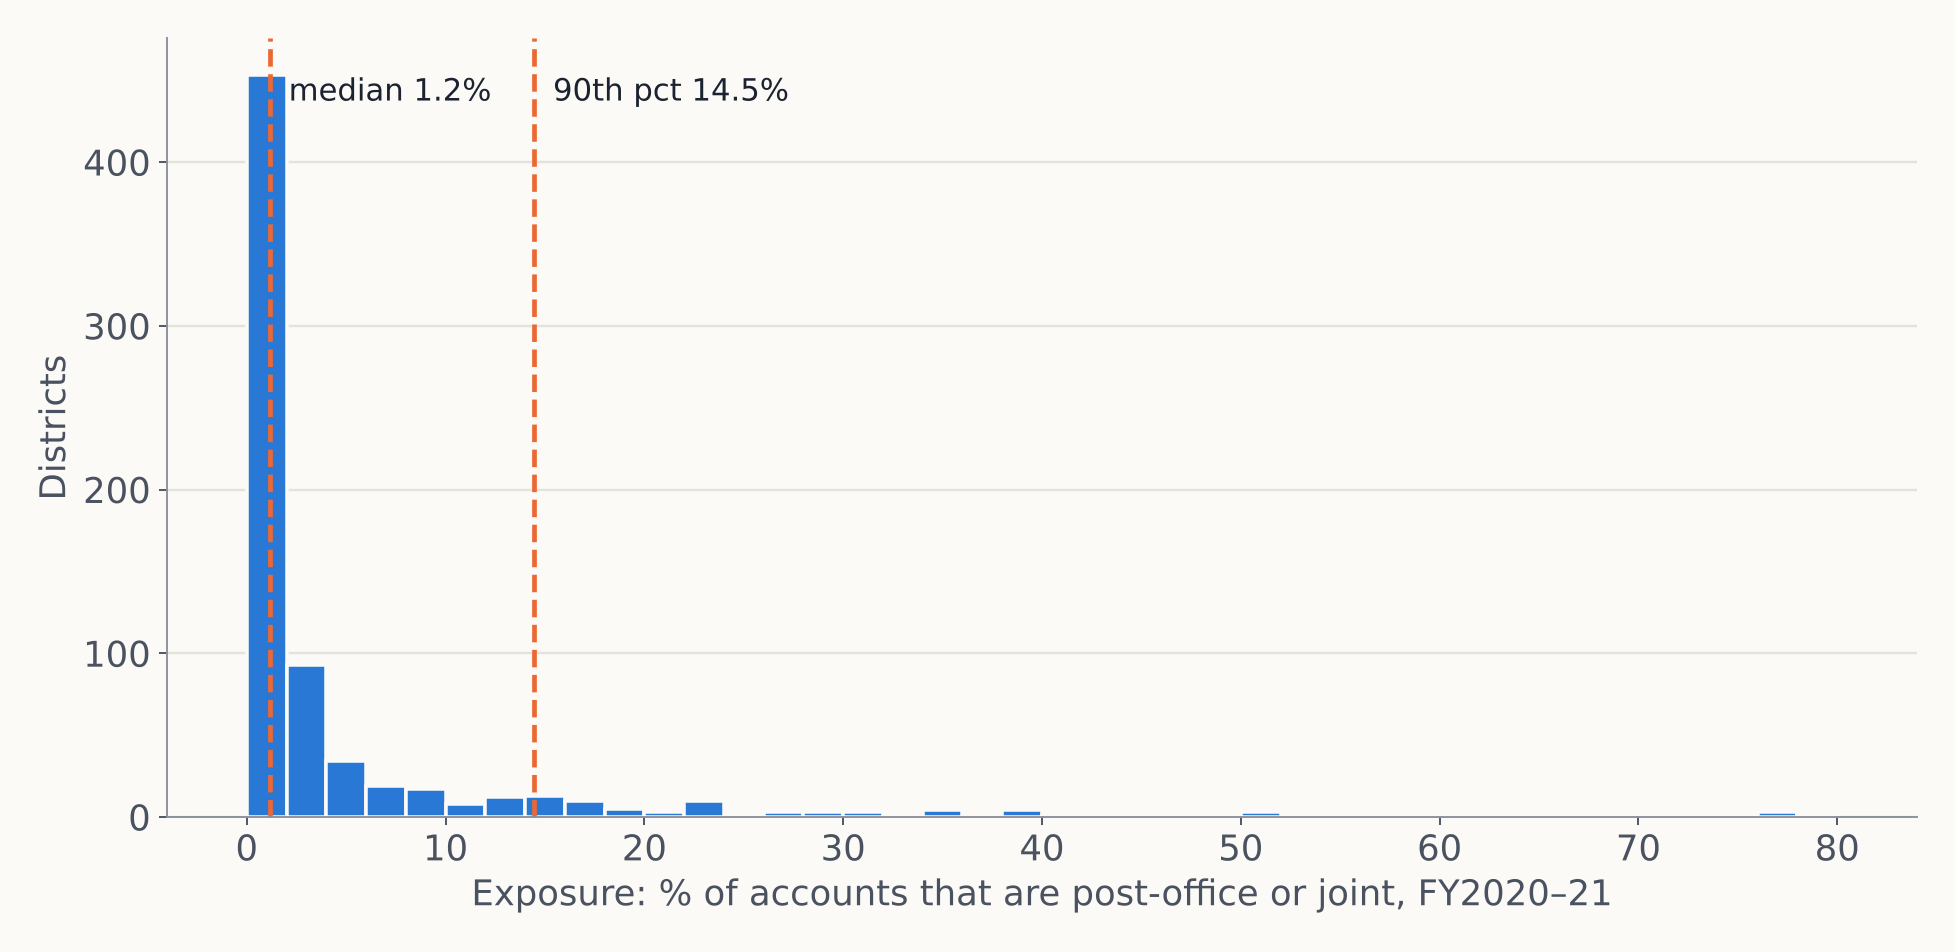

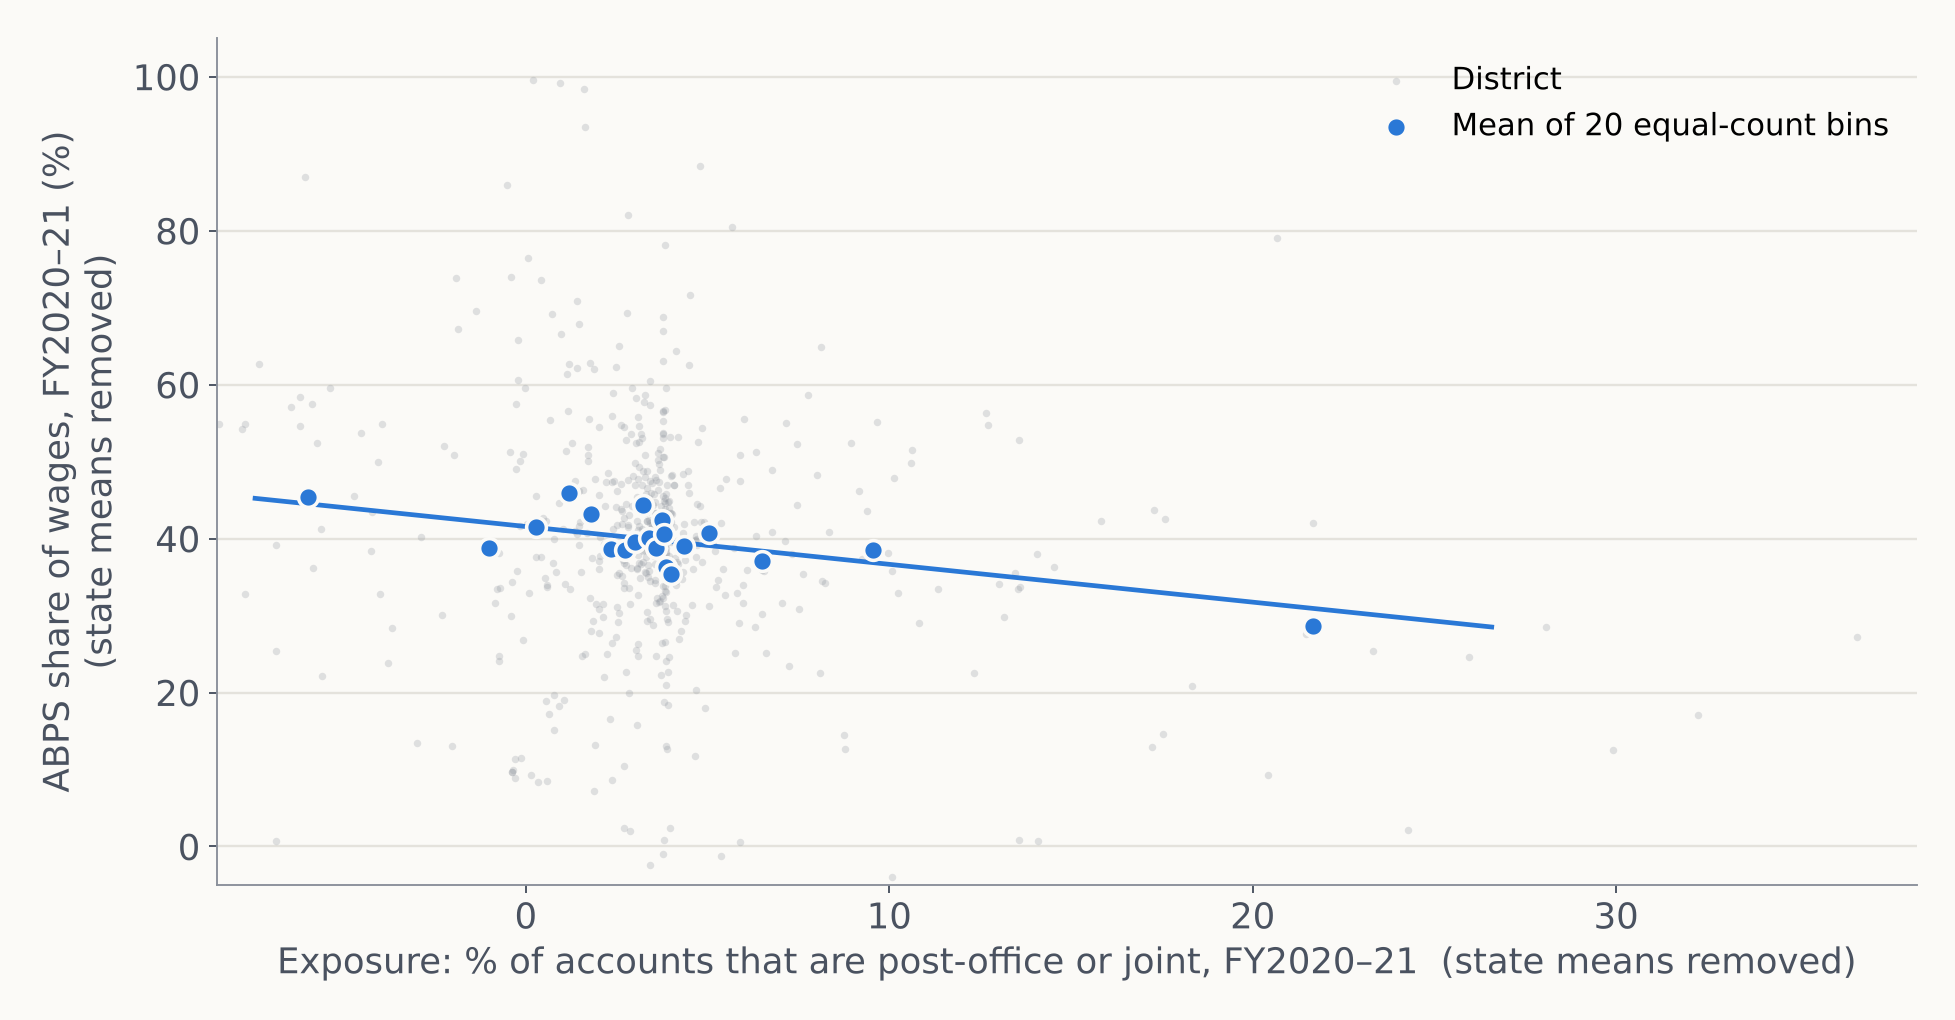

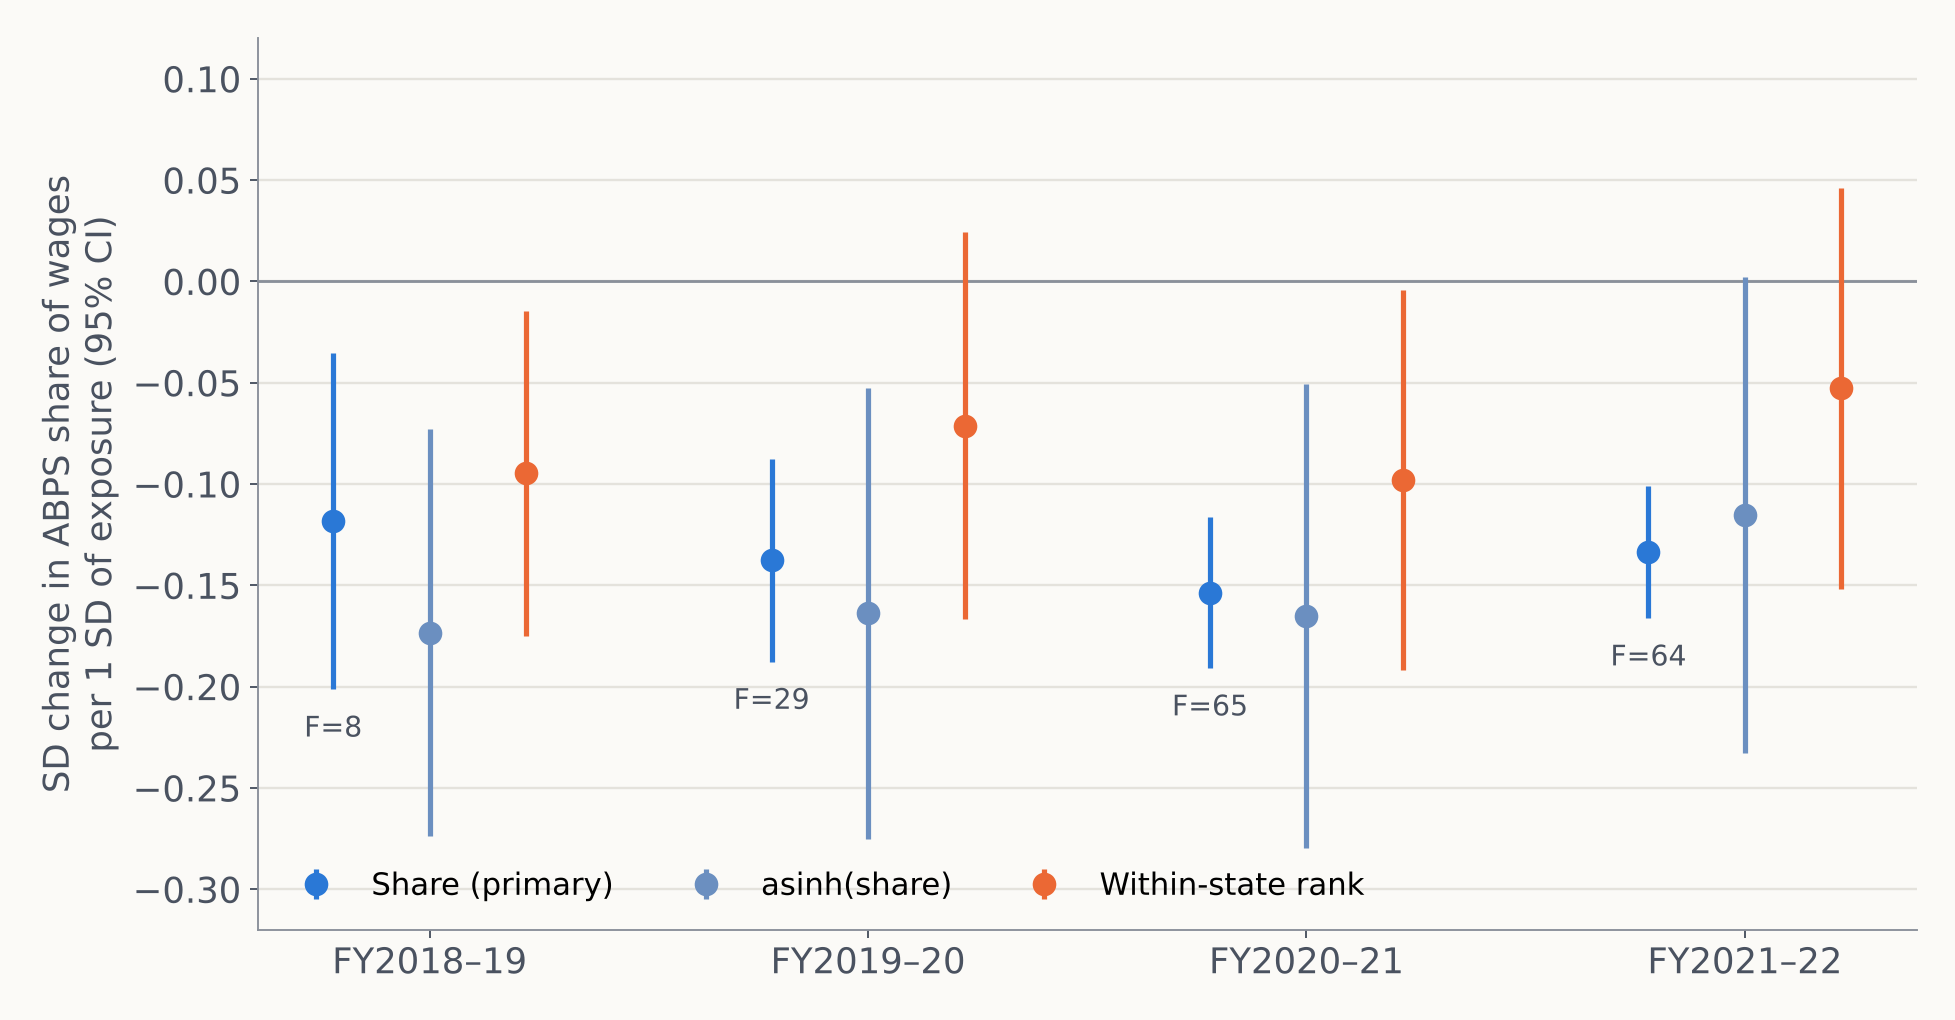

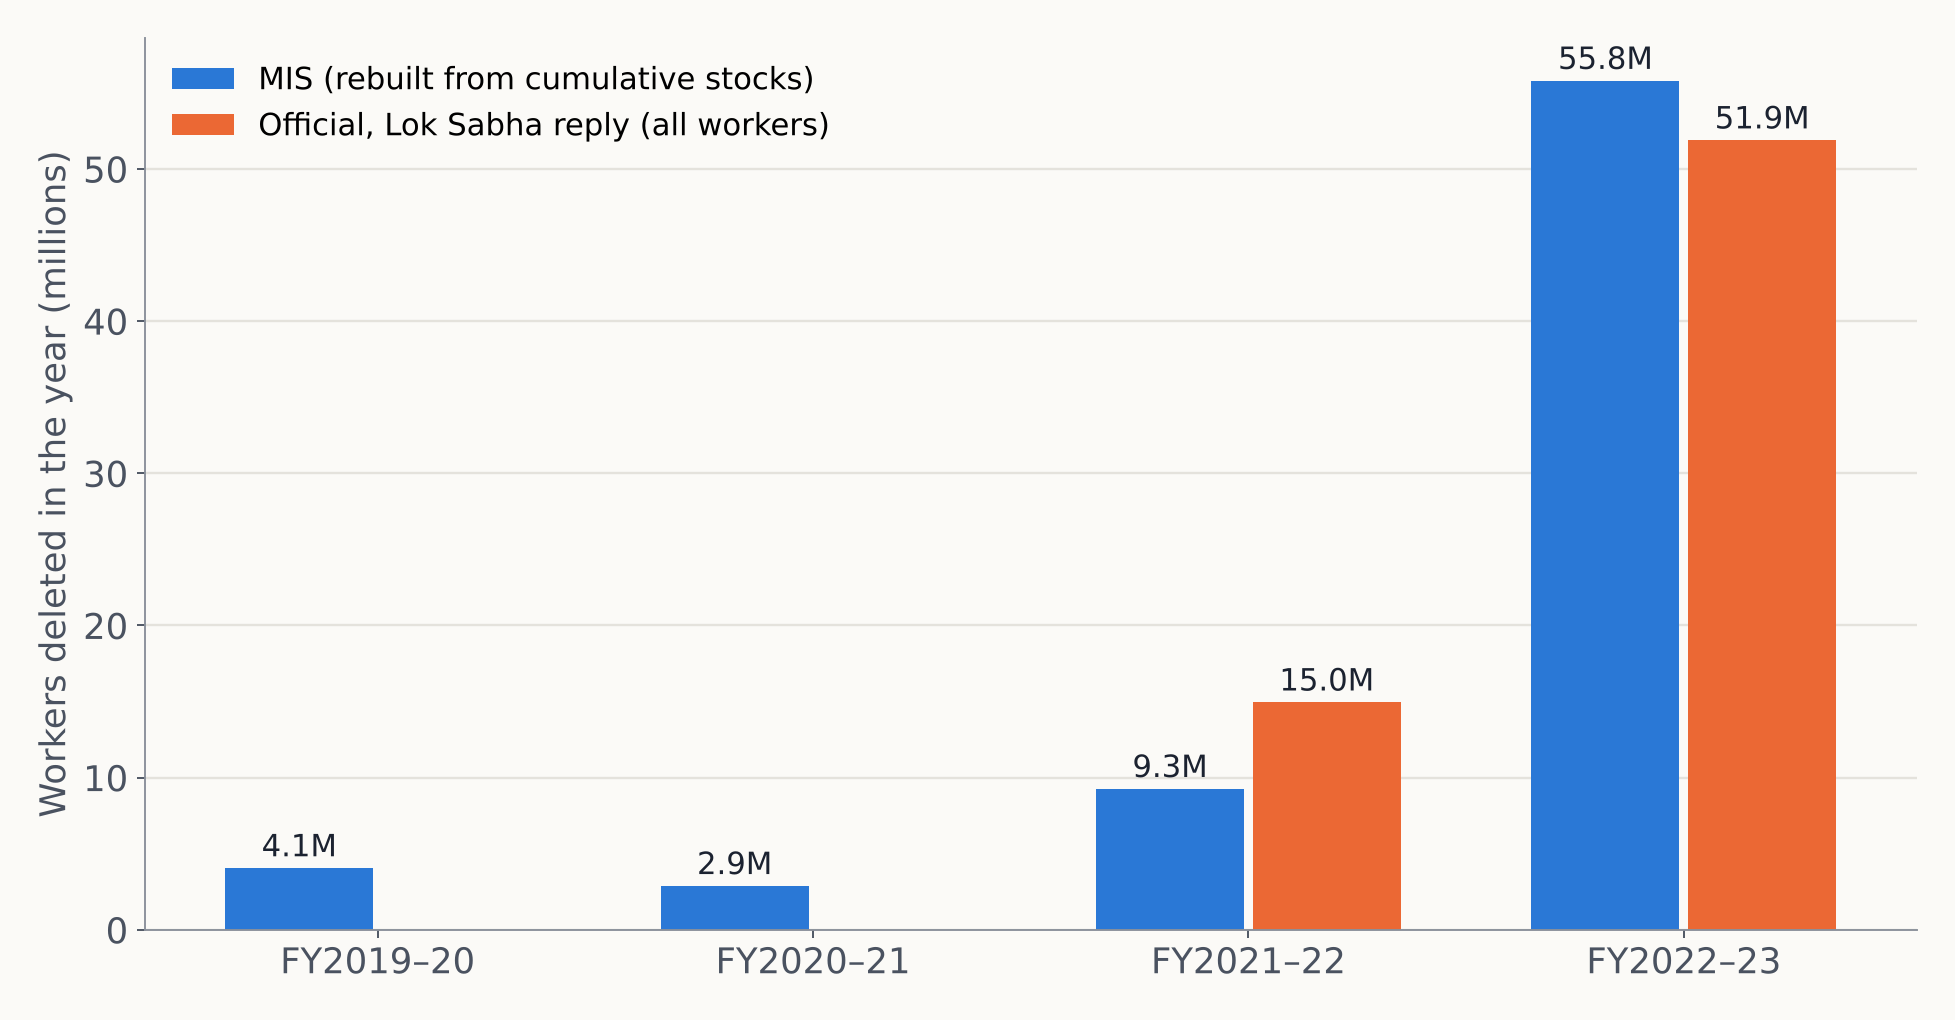

In [12]:
for f in (exposure_hist(), binscatter(), coef_by_spec(), deletions_audit()):
    show(f)

## 6. Stage 1: difference-in-differences
Main treatment: high-friction district (top within-state decile of exposure), × post (FY2022–23 on).
District FE + state × year FE, SEs clustered by state. Secondary: quartiles, continuous exposure,
components, direct readiness, timing and trend checks, placebo, PPML counts, and a Wald-DiD that
rescales the effect per 10-point lower ABPS share.

In [13]:
"""
Stage 1: difference-in-differences of worker deletions on ABPS conversion friction.

Implements the four design changes fixed after Stage 0 (protocol v2):
  1. Main treatment = high-friction indicator (top within-state decile of FY2020-21 exposure);
     within-state exposure quartiles and the continuous share are secondary.
  2. Joint-account share is reported as the leading component; the direct readiness measure
     (1 - FY2021-22 ABPS share of wages) is the alternative exposure.
  3. Every reduced-form estimate sits beside its first stage; a Wald-DiD rescales the
     high-friction estimate per 10-point lower ABPS share, with a state-cluster bootstrap CI.
  4. Pre-period guard: event-study leads, an exposure-specific-trend check, and a
     timing-shift check that drops FY2021-22.

Outcome: all-worker deletions per 1,000 non-deleted registered workers at the start of the FY
(OLS, district FE + state-by-year FE, SEs clustered by state). PPML on the deletion count with
log(start-of-year stock) as offset is the count-model robustness check.

Post period = FY2022-23 onward (ABPS order of 30 Jan 2023 falls in FY2022-23; mandate binding
from 1 Jan 2024 falls in FY2023-24). Reference year for the event study = FY2021-22.

Usage: python src/did_analysis.py
"""
from __future__ import annotations

import json
import sys
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt  # noqa: E402
import numpy as np  # noqa: E402
import pandas as pd  # noqa: E402


ROOT = PROJECT_ROOT
TAB, FIG = ROOT / "outputs" / "tables", ROOT / "outputs" / "figures"
for p in (TAB, FIG):
    p.mkdir(parents=True, exist_ok=True)

POST_START = "2022-2023"
REF_YEAR = "2021-2022"
BLUE, ORANGE, INK2, MUTED, GRID = "#2a78d6", "#eb6834", "#4A5260", "#8A909A", "#E4E2DC"


def zstd(s: pd.Series) -> pd.Series:
    return (s - s.mean()) / s.std()


def build_panel() -> tuple[pd.DataFrame, dict]:
    p = pd.read_csv(ROOT / "data" / "processed" / "deletions_district_panel.csv")
    e = pd.read_csv(ROOT / "data" / "processed" / "stage0_analysis_frame_2020-2021.csv")
    e = e[["state", "district", "expo", "po_share", "joint_share", "abps_share@2020-2021", "abps_share@2021-2022"]]
    # high-friction = top within-state decile; only states with >= 5 districts can define a decile
    e["n_state"] = e.groupby("state").district.transform("size")
    e["pct"] = e.groupby("state").expo.rank(pct=True, method="average")
    e["high"] = ((e.pct > 0.9) & (e.n_state >= 5)).astype(float)
    e["quart"] = np.ceil(4 * e.pct).clip(1, 4).astype(int)
    e["readiness_gap"] = 1 - e["abps_share@2021-2022"]
    d = p.merge(e, on=["state", "district"], how="inner")
    info = {"panel_rows_before_merge": int(len(p)), "rows_matched_to_exposure": int(len(d))}
    d["post"] = (d.fy >= POST_START).astype(float)
    d["state_year"] = d.state + "_" + d.fy
    # outcome: negative net deletions (restorations / record revisions) are excluded, counted
    info["negative_rows_excluded"] = int(d.neg_flag.sum())
    d = d[~d.neg_flag].copy()
    lo, hi = d.del_rate_per_1000.quantile([0.01, 0.99])
    d["rate_w"] = d.del_rate_per_1000.clip(lo, hi)
    info["winsor_bounds_per_1000"] = [float(lo), float(hi)]
    d["log_stock"] = np.log(d.stock_start)
    d["deletions"] = d.worker_deletions.clip(lower=0)
    for v in ("expo", "joint_share", "po_share", "readiness_gap"):
        d[f"{v}_z"] = zstd(d[v])
    d["high_post"] = d.high * d.post
    for q in (2, 3, 4):
        d[f"q{q}_post"] = (d.quart == q).astype(float) * d.post
    for v in ("expo_z", "joint_share_z", "po_share_z", "readiness_gap_z"):
        d[f"{v}_post"] = d[v] * d.post
    years = sorted(d.fy.unique())
    info["years"] = years
    info["districts"] = int(d.district.nunique())
    info["states"] = int(d.state.nunique())
    info["high_friction_districts"] = int(d.drop_duplicates(["state", "district"]).high.sum())
    return d, info


def row(name: str, r, var: str, extra: dict | None = None) -> dict:
    out = {"spec": name, "coef": r.params[var], "se": r.se[var], "p": r.pvalue[var],
           "ci_lo": r.params[var] - 1.96 * r.se[var], "ci_hi": r.params[var] + 1.96 * r.se[var],
           "N": r.nobs, "clusters": r.n_clusters}
    out.update(extra or {})
    return out


def main() -> dict:
    d, info = build_panel()
    FE = ["district", "state_year"]
    rows = []
    pre_mean_high = d[(d.post == 0) & (d.high == 1)].rate_w.mean()
    info["pre_mean_rate_high"] = float(pre_mean_high)
    info["pre_mean_rate_all"] = float(d[d.post == 0].rate_w.mean())
    info["post_mean_rate_all"] = float(d[d.post == 1].rate_w.mean())

    # (1) main: high-friction indicator
    r = feols(d, "rate_w", ["high_post"], fe=FE, cluster="state")
    rows.append(row("Main: high-friction × post (per 1,000)", r, "high_post"))
    main_b, main_se = r.params["high_post"], r.se["high_post"]
    # (2) quartiles
    rq = feols(d, "rate_w", ["q2_post", "q3_post", "q4_post"], fe=FE, cluster="state")
    for q in (2, 3, 4):
        rows.append(row(f"Quartile {q} vs Q1 × post", rq, f"q{q}_post"))
    # (3) continuous exposures (per SD)
    for v, lab in (("expo_z", "Continuous exposure (per SD) × post"),
                   ("joint_share_z", "Joint-account share (per SD) × post"),
                   ("po_share_z", "Post-office share (per SD) × post"),
                   ("readiness_gap_z", "Direct: 1 − FY2021–22 ABPS share (per SD) × post")):
        rv = feols(d, "rate_w", [f"{v}_post"], fe=FE, cluster="state")
        rows.append(row(lab, rv, f"{v}_post"))
    # (4) pre-period guards
    dn = d[d.fy != REF_YEAR]
    rt = feols(dn, "rate_w", ["high_post"], fe=FE, cluster="state")
    rows.append(row("Timing check: drop FY2021–22", rt, "high_post"))
    d["trend"] = d.fy.str[:4].astype(int) - 2019
    d["high_trend"] = d.high * d.trend
    rtr = feols(d, "rate_w", ["high_post", "high_trend"], fe=FE, cluster="state")
    rows.append(row("With high-friction linear trend", rtr, "high_post"))
    dpre = d[d.post == 0].copy()
    dpre["placebo"] = dpre.high * (dpre.fy == REF_YEAR)
    rpl = feols(dpre, "rate_w", ["placebo"], fe=FE, cluster="state")
    rows.append(row("Placebo: FY2021–22 as fake post (pre years only)", rpl, "placebo"))
    # (5) PPML count model
    rp = ppml(d, "deletions", ["high_post"], fe=FE, cluster="state", offset="log_stock")
    rows.append(row("PPML count, offset log stock (semi-elasticity)", rp, "high_post",
                    {"pct_effect": float(np.expm1(rp.params["high_post"]) * 100)}))
    rpc = ppml(d, "deletions", ["expo_z_post"], fe=FE, cluster="state", offset="log_stock")
    rows.append(row("PPML count, continuous exposure (per SD)", rpc, "expo_z_post",
                    {"pct_effect": float(np.expm1(rpc.params["expo_z_post"]) * 100)}))
    # (6) raw (unwinsorised) outcome
    rr = feols(d, "del_rate_per_1000", ["high_post"], fe=FE, cluster="state")
    rows.append(row("Unwinsorised rate", rr, "high_post"))
    res = pd.DataFrame(rows)
    res.to_csv(TAB / "did_results.csv", index=False)

    # (7) event study
    years = sorted(d.fy.unique())
    ev_vars = []
    for y in years:
        if y == REF_YEAR:
            continue
        c = f"ev_{y[:4]}"
        d[c] = d.high * (d.fy == y)
        ev_vars.append((y, c))
    re_ = feols(d, "rate_w", [c for _, c in ev_vars], fe=FE, cluster="state")
    ev = pd.DataFrame([{"fy": y, "coef": re_.params[c], "se": re_.se[c], "p": re_.pvalue[c]} for y, c in ev_vars]
                      + [{"fy": REF_YEAR, "coef": 0.0, "se": 0.0, "p": np.nan}]).sort_values("fy")
    ev.to_csv(TAB / "did_event_study.csv", index=False)
    lead_vars = [c for y, c in ev_vars if y < REF_YEAR]
    # joint test of leads = 0 (Wald, cluster-robust)
    if lead_vars:
        b = re_.params[lead_vars].to_numpy()
        se = re_.se[lead_vars].to_numpy()
        info["lead_coefs"] = dict(zip(lead_vars, b.round(3).tolist()))
        info["max_abs_lead_t"] = float(np.max(np.abs(b / se)))

    # (8) first stage + Wald-DiD with state-cluster bootstrap
    st = d.drop_duplicates(["state", "district"])[["state", "district", "high", "abps_share@2020-2021"]].dropna()
    st["abps_pct"] = 100 * st["abps_share@2020-2021"]
    st = st[st["abps_share@2020-2021"] <= 1.05]
    fs = feols(st, "abps_pct", ["high"], fe=["state"], cluster="state")
    pi, pi_se = fs.params["high"], fs.se["high"]
    info["first_stage_pp"] = float(pi)
    info["first_stage_se"] = float(pi_se)
    info["first_stage_F"] = float((pi / pi_se) ** 2)
    wald = main_b / (-pi / 10)  # per 10-pp LOWER ABPS share
    rng = np.random.default_rng(2026)
    states = d.state.unique()
    boot = []
    for _ in range(300):
        pick = rng.choice(states, size=len(states), replace=True)
        parts_d, parts_s = [], []
        for i, s_ in enumerate(pick):
            a = d[d.state == s_].copy(); a["state"] = f"{s_}#{i}"; a["district"] = a.district + f"#{i}"
            a["state_year"] = a.state + "_" + a.fy
            b_ = st[st.state == s_].copy(); b_["state"] = f"{s_}#{i}"
            parts_d.append(a); parts_s.append(b_)
        bd, bs = pd.concat(parts_d), pd.concat(parts_s)
        if bd.high_post.sum() == 0 or bs.high.sum() == 0:
            continue
        try:
            rb = feols(bd, "rate_w", ["high_post"], fe=FE)
            fb = feols(bs, "abps_pct", ["high"], fe=["state"])
            if abs(fb.params["high"]) > 1e-6:
                boot.append(rb.params["high_post"] / (-fb.params["high"] / 10))
        except Exception:
            continue
    boot = np.array(boot)
    info["wald_did_per_10pp"] = float(wald)
    info["wald_boot_ci95"] = [float(np.percentile(boot, 2.5)), float(np.percentile(boot, 97.5))] if len(boot) > 50 else None
    info["wald_boot_reps"] = int(len(boot))

    # figure: event study
    fig, ax = plt.subplots(figsize=(11.5, 6.0), dpi=170)
    x = np.arange(len(ev))
    ax.axhline(0, color=MUTED, lw=1.2)
    post_mask = ev.fy >= POST_START
    ax.axvspan(x[post_mask.to_numpy()].min() - 0.5 if post_mask.any() else len(ev), len(ev) - 0.5, color="#F3E6DD", zorder=0)
    ax.errorbar(x, ev.coef, yerr=1.96 * ev.se, fmt="o", ms=10, color=BLUE, ecolor=BLUE, elinewidth=2.4, capsize=0, zorder=3)
    for xi, (_, r_) in zip(x, ev.iterrows()):
        lab = "ref." if r_.fy == REF_YEAR else f"{r_.coef:+.1f}"
        ax.annotate(lab, (xi, r_.coef), xytext=(14, 0), textcoords="offset points", va="center", fontsize=13, color=INK2)
    ax.set_xticks(x, [f"FY{f[:4]}–{f[-2:]}" for f in ev.fy])
    ax.set_ylabel("High-friction minus other districts\n(deletions per 1,000 workers, 95% CI)")
    ax.yaxis.grid(True, color=GRID, lw=1)
    ax.set_axisbelow(True)
    ax.text(x[post_mask.to_numpy()].min() if post_mask.any() else 0, ax.get_ylim()[1] * 0.92, "  ABPS period", color="#B4461A", fontsize=13)
    for s_ in ("top", "right"):
        ax.spines[s_].set_visible(False)
    fig.tight_layout()
    fig.savefig(FIG / "fig_event_study.png")
    plt.close(fig)

    # figure: national level (left) and within-state gap (right)
    g = d.groupby(["fy", "high"]).rate_w.mean().unstack()
    d["rate_ws"] = d.rate_w - d.groupby("state_year").rate_w.transform("mean")
    gw = d.groupby(["fy", "high"]).rate_ws.mean().unstack()
    fig, axes = plt.subplots(1, 2, figsize=(11.5, 6.0), dpi=170)
    xs = np.arange(len(g))
    labs = [f"FY{f[:4][2:]}–{f[-2:]}" for f in g.index]
    ax = axes[0]
    ax.plot(xs, g[1.0], "-o", color=ORANGE, lw=2.4, ms=9, label="High-friction (top within-state decile)")
    ax.plot(xs, g[0.0], "-o", color=BLUE, lw=2.4, ms=9, label="Other districts")
    ax.set_xticks(xs, labs)
    ax.set_title("Mean deletions per 1,000 workers", fontsize=14, loc="left")
    ax.yaxis.grid(True, color=GRID, lw=1)
    ax.set_axisbelow(True)
    ax.legend(frameon=False, loc="upper left", fontsize=12)
    for s_ in ("top", "right"):
        ax.spines[s_].set_visible(False)
    ax = axes[1]
    ax.axhline(0, color=MUTED, lw=1.2)
    ax.plot(xs, gw[1.0], "-o", color=ORANGE, lw=2.4, ms=9)
    ax.plot(xs, gw[0.0], "-o", color=BLUE, lw=2.4, ms=9)
    ax.set_xticks(xs, labs)
    ax.set_title("Same, minus own state-year mean", fontsize=14, loc="left")
    (TAB / "did_group_means.csv").write_text(pd.concat({"mean": g, "within_state": gw}, axis=1).to_csv())
    ax.yaxis.grid(True, color=GRID, lw=1)
    ax.set_axisbelow(True)
    for s_ in ("top", "right"):
        ax.spines[s_].set_visible(False)
    fig.tight_layout()
    fig.savefig(FIG / "fig_raw_trends.png")
    plt.close(fig)


    info["main"] = {"coef": float(main_b), "se": float(main_se), "p": float(res.iloc[0].p)}
    (ROOT / "outputs" / "did_summary.json").write_text(json.dumps(info, indent=2, default=float))
    return {"info": info, "res": res, "ev": ev}

{
 "years": [
  "2019-2020",
  "2020-2021",
  "2021-2022",
  "2022-2023"
 ],
 "districts": 706,
 "states": 33,
 "high_friction_districts": 85,
 "negative_rows_excluded": 207,
 "first_stage_pp": -6.785679684419063,
 "first_stage_F": 9.301587213800644,
 "wald_did_per_10pp": -1.7386206965742121,
 "wald_boot_ci95": [
  -40.76728268019238,
  22.12204476735866
 ]
}


,spec,coef,se,p,ci_lo,ci_hi,N,clusters
0,"Main: high-friction × post (per 1,000)",-1.180,9.295,0.900,-19.398,17.039,2594,33
1,Quartile 2 vs Q1 × post,-4.705,8.802,0.597,-21.956,12.547,2594,33
2,Quartile 3 vs Q1 × post,3.455,11.566,0.767,-19.214,26.124,2594,33
3,Quartile 4 vs Q1 × post,6.382,14.559,0.664,-22.154,34.919,2594,33
4,Continuous exposure (per SD) × post,-0.202,2.334,0.932,-4.775,4.372,2594,33
5,Joint-account share (per SD) × post,-2.178,3.298,0.514,-8.643,4.287,2594,33
6,Post-office share (per SD) × post,1.389,0.625,0.033,0.164,2.613,2594,33
7,Direct: 1 − FY2021–22 ABPS share (per SD) × post,3.445,8.361,0.683,-12.942,19.831,2185,30
8,Timing check: drop FY2021–22,-2.885,9.923,0.773,-22.333,16.563,1943,33
9,With high-friction linear trend,-13.317,16.073,0.414,-44.820,18.187,2594,33


,fy,coef,se,p
0,2019-2020,-12.190,9.167,0.193
1,2020-2021,8.668,6.107,0.165
3,2021-2022,0.000,0.000,NaN
2,2022-2023,-2.442,10.258,0.813


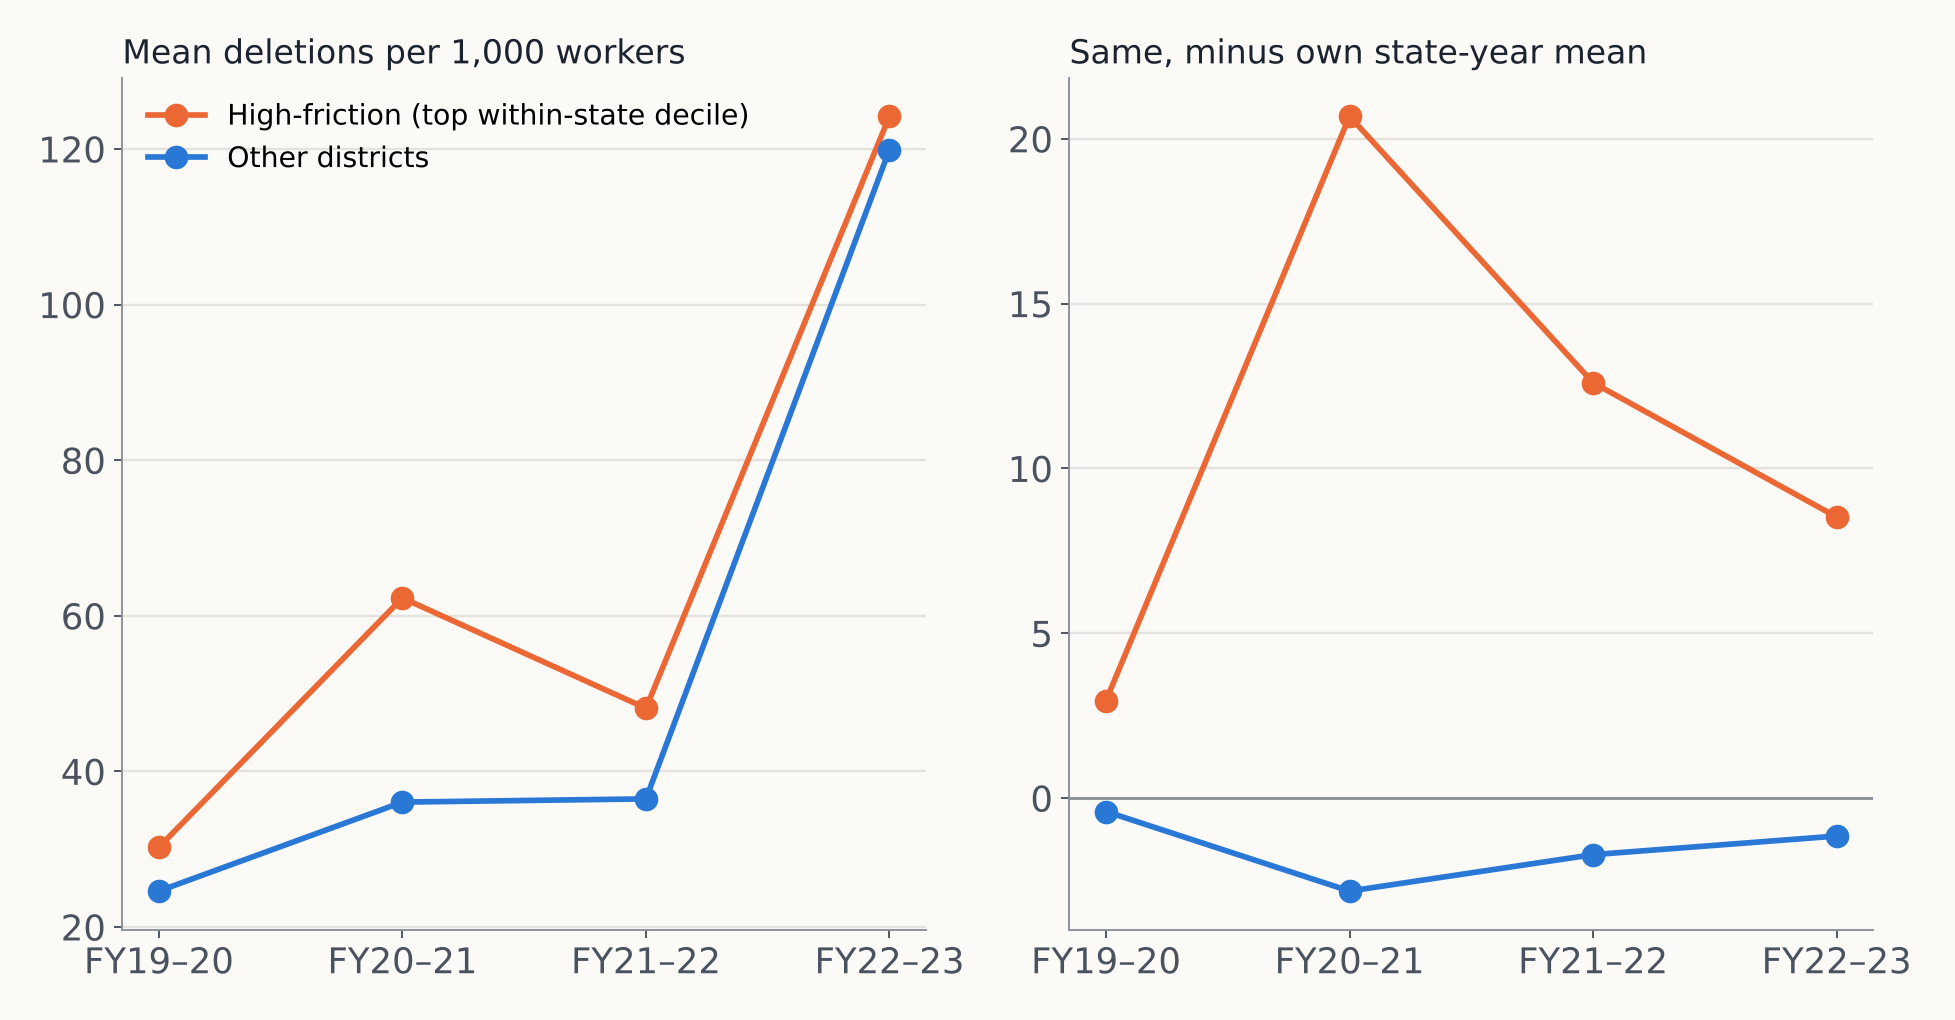

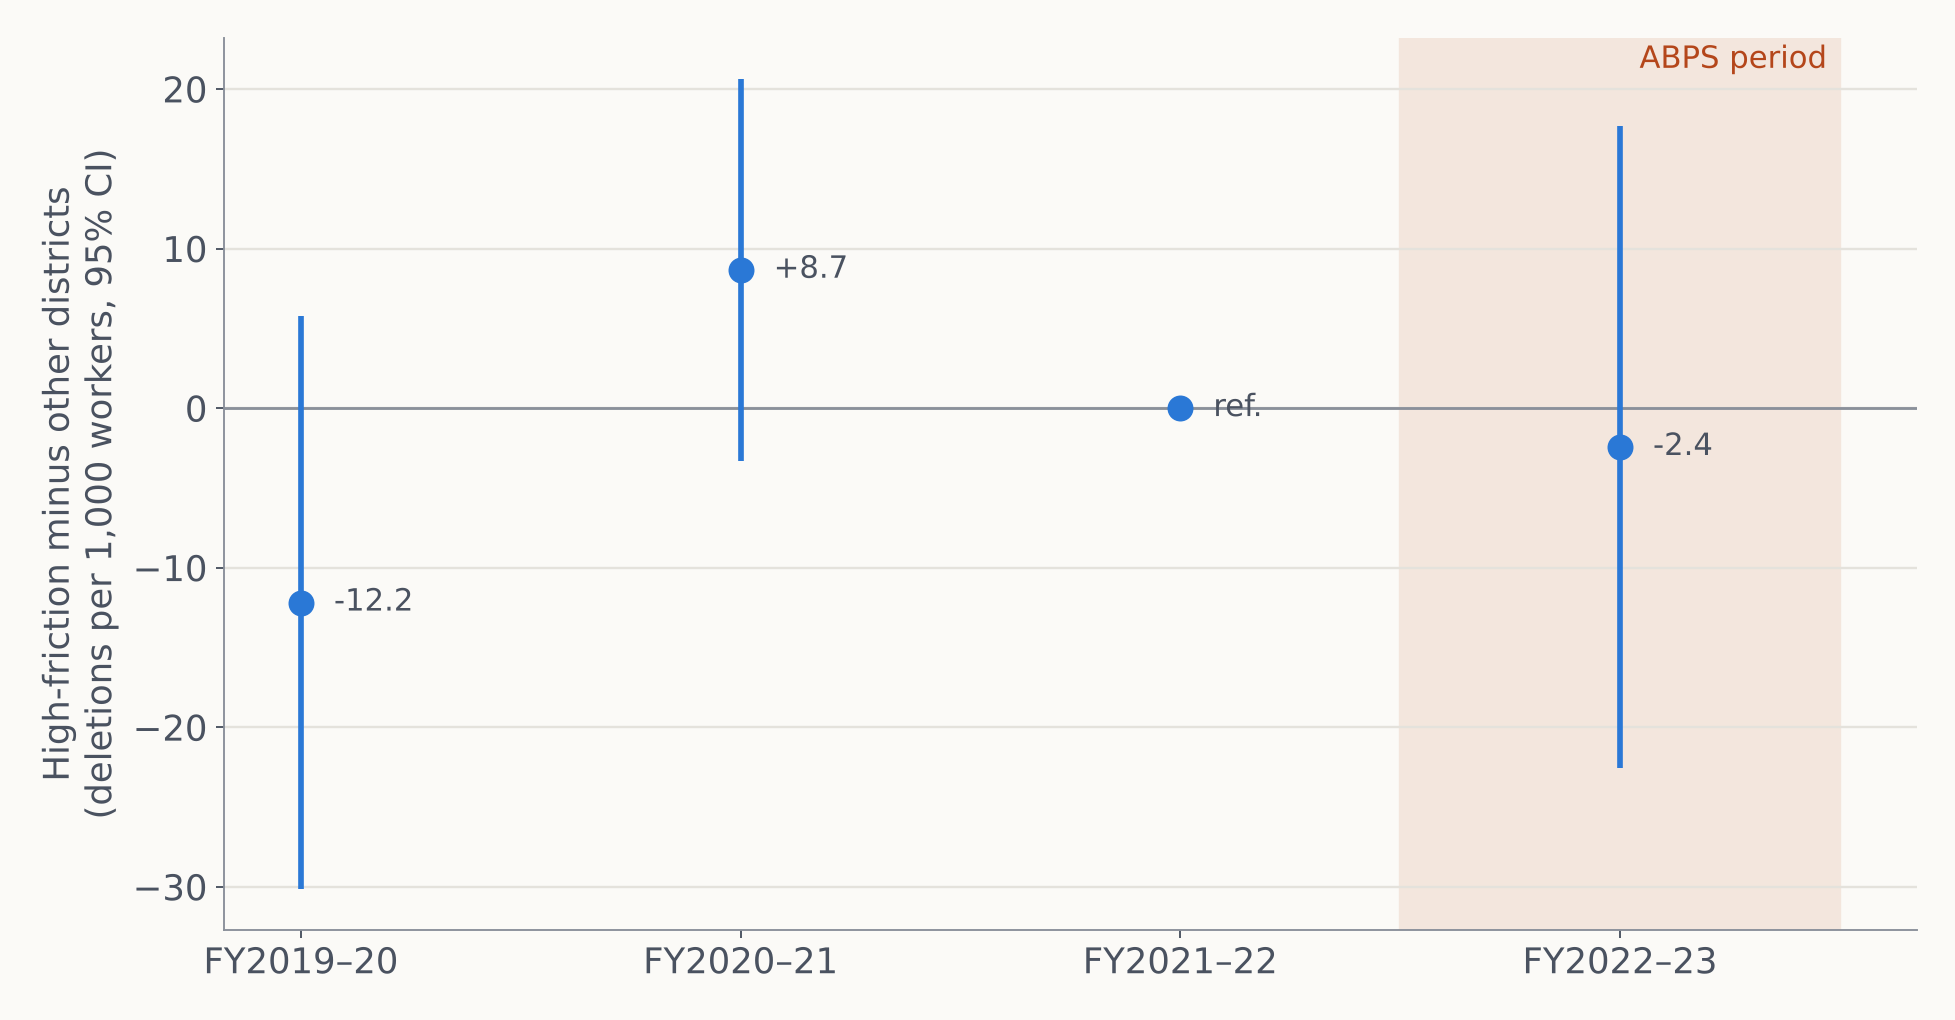

In [14]:
out = main()
display(out["res"][["spec", "coef", "se", "p", "ci_lo", "ci_hi", "N", "clusters"]].round(3))
display(out["ev"].round(3))
info = out["info"]
print(json.dumps({k: info[k] for k in ("years", "districts", "states", "high_friction_districts", "negative_rows_excluded",
                                       "first_stage_pp", "first_stage_F", "wald_did_per_10pp", "wald_boot_ci95")}, indent=1, default=float))
show(PROJECT_ROOT / "outputs/figures/fig_raw_trends.png")
show(PROJECT_ROOT / "outputs/figures/fig_event_study.png")

## 7. Conclusions
* **Stage 0 (proxy validation): GO, with conditions.** The FY2020–21 account mix predicts lower
  pre-mandate ABPS use within states (F = 29–65 in three of four years, stable when any state is
  dropped), but the link is weak (≈3% of within-state variance) and sits in the high-exposure tail.
* **Stage 1 (DiD, post = FY2022–23).** High-friction districts did **not** see a larger rise in deletions:
  -1.2 per 1,000 workers (SE 9.3, p = 0.90), 95% CI [-19.4, 17.0].
  They already deleted more than the rest of their state before ABPS, and that gap did not widen.
* **Robustness.** 12 of 14 specifications are not significant at 5%. The two exceptions point
  in opposite directions: the post-office share alone shows a small rise (+1.4 per 1,000 per SD,
  p = 0.03), while the count model with continuous exposure shows proportionally fewer deletions
  (-14% per SD, p = 0.01). Neither supports a robust friction effect.
* **Scaled by the first stage** (high-friction districts had a 6.8-point lower ABPS share,
  F = 9.3), the Wald-DiD is -1.7 deletions per 1,000 per 10-point lower
  readiness, bootstrap 95% CI [-40.8, 22.1]: too wide to rule out moderate effects.
* **Limits.** Only FY2022–23 is post-mandate in this extract; the order came on 30 Jan 2023, late in that year, and ABPS became binding in FY2023–24, so the effect may not be visible yet. The MIS records 5.7M fewer deletions than the official figure in FY2021–22 and
  3.9M more in FY2022–23, and eligibility data exist only as today's snapshot. Results are
  associations under parallel trends, not proof of wrongful exclusion.